In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/apsood/metrological-vars-data/open-meteo-47.56N122.12W103m (1).csv
/kaggle/input/datasets/apsood/sammamish-pm2-5-data/Lake_Sammamish_Daily_PA_data (2).csv
/kaggle/input/datasets/apsood/nasa-firms-wildfire-data/NASA Firms Wildfire Data (1).csv


## Data Preprocessing

The cells below load and clean the raw PurpleAir PM2.5, weather, and NASA FIRMS wildfire data, then engineer the daily features and prediction targets used later for modeling.

In [2]:
# ===================== CELL 1 =====================
import os, re, glob, json, warnings
import numpy as np
import pandas as pd
 
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 100)
 
# ---------------- STUDY DESIGN CONFIG ----------------
WINDOW_START = pd.Timestamp("2021-01-03")
WINDOW_END   = pd.Timestamp("2026-01-03")

# Chose 4 sensors out of 32 because these have most contiguous data across the complete target period
SENSOR_IDS = [77531, 81955, 87327, 94341]   # Syndicate Homebase, Timberline CC, Inglewood Hill, Ardmore
 
SITE_LAT, SITE_LON = 47.60, -122.06         # Sammamish study-area centroid, for fire distances
 
HORIZONS = [1, 2]                           # predict PM2.5 at t+1 and t+2 days
 
WIND_LEVEL        = "100m"                  # wind_x / wind_y built from the 100 m wind
INCLUDE_10M_WIND  = True                    # keep 10 m speed too (surface dispersion, not redundant)
 
MAX_INTERP_GAP          = 2      # interpolate PM2.5 gaps of <= this many days, within a sensor only
MIN_LAG_HISTORY_DAYS    = 7      # drop each sensor's first N days (no full lag history)
MIN_SENSORS_REGIONAL    = 3      # need >= this many sensors reporting to trust the regional median
TARGET_MUST_BE_OBSERVED = True   # never train on an interpolated target value
 
FIRE_RADII_KM   = [25, 50, 100]
NO_FIRE_DIST_KM = 500.0          # placeholder distance on days with zero detections in the FIRMS box
FIRE_KEEP_TYPES = [0]            # 0 = presumed vegetation fire (drops static land sources / offshore)
FIRE_MIN_CONF   = ["n", "h"]     # nominal + high confidence (drops 'l' = low)

# Distribution of the datset across Training, Validation and Testing
TRAIN_END = pd.Timestamp("2023-12-31")   # train = 2021-2023 | val = 2024 | test = 2025
VAL_END   = pd.Timestamp("2024-12-31")
EMBARGO_DAYS = max(HORIZONS)     # gap between splits so a train target can't sit inside val/test
 
# "Elevated PM2.5" is defined from the TRAINING split's own distribution rather than an
# absolute EPA number: Sammamish is a clean suburban area where 35 ug/m3 almost never occurs.
ELEVATED_PCTL = 0.95
SEVERE_PCTL   = 0.98
EPA_THRESHOLD = 35.0             # kept as a reference mask only
 
OUT_DIR = "/kaggle/working" if os.name == "posix" and os.path.isdir("/kaggle/working") else "."
 
# ---------------- FIND THE INPUT FILES ----------------
SEARCH_ROOTS = ["/kaggle/input", "."]
_all = []
for root in SEARCH_ROOTS:
    if os.path.isdir(root):
        _all += glob.glob(os.path.join(root, "**", "*.csv"), recursive=True)
 
def find_file(patterns, label, must_contain=None):
    cands = []
    for p in patterns:
        cands += [f for f in _all if re.search(p, os.path.basename(f), re.I)]
    cands = sorted(dict.fromkeys(cands))
    if must_contain:                       # prefer a file whose header actually has this text
        good = []
        for f in cands:
            try:
                head = "".join(open(f, encoding="utf-8", errors="ignore").readlines()[:6]).lower()
                if must_contain.lower() in head:
                    good.append(f)
            except Exception:
                pass
        if good:
            cands = good
    if not cands:
        raise FileNotFoundError(
            f"Could not find the {label} CSV.\nLooked in {SEARCH_ROOTS}.\nSaw:\n  "
            + "\n  ".join(sorted(os.path.basename(f) for f in _all)))
    return cands[0]

# Load all the data. 
# PA - purple air data 
PA_PATH   = find_file([r"purple", r"_PA_", r"PA_data", r"sammamish.*daily"], "PurpleAir PM2.5")
# Open meteo - Met data
MET_PATH  = find_file([r"openmeteo", r"metro", r"meteo", r"weather", r"noaa"],
                      "meteorological", must_contain="wind_direction")
# Fire data from NASA FIRMS
FIRE_PATH = find_file([r"firms", r"wildfire", r"fire"], "NASA FIRMS wildfire")
 
print("PurpleAir :", os.path.basename(PA_PATH))
print("Weather   :", os.path.basename(MET_PATH))
print("Wildfire  :", os.path.basename(FIRE_PATH))
print(f"\nStudy window : {WINDOW_START.date()} -> {WINDOW_END.date()}  "
      f"({(WINDOW_END-WINDOW_START).days+1} days)")
print("Sensors      :", SENSOR_IDS)
print("Horizons     :", [f"t+{h}d" for h in HORIZONS])
print("Wind level   :", WIND_LEVEL)


# for the output, add visuals (graphs, plots, etc.)

PurpleAir : Lake_Sammamish_Daily_PA_data (2).csv
Weather   : open-meteo-47.56N122.12W103m (1).csv
Wildfire  : NASA Firms Wildfire Data (1).csv

Study window : 2021-01-03 -> 2026-01-03  (1827 days)
Sensors      : [77531, 81955, 87327, 94341]
Horizons     : ['t+1d', 't+2d']
Wind level   : 100m


### Load PurpleAir PM2.5 and build the modeling panel

Loads the raw PurpleAir sensor CSV, cleans it, derives a regional PM2.5 signal, then reindexes the four modeled sensors onto continuous daily calendars.

- **Load & clean**: parses `date`, drops unparseable rows, sets negative `pm25_cal` readings to missing (invalid), and keeps large values (they are the smoke events being studied). Drops duplicate sensor-day rows.
- **Regional signal**: computes `regional_pm25_median` / `_mean` / `_n_sensors` per day from **all** sensors in the window (not just the four modeled ones), and blanks it out on days with fewer than `MIN_SENSORS_REGIONAL` reporting.
- **Per-sensor daily calendar**: for each of the four `SENSOR_IDS`, reindexes onto a continuous daily date range so later `shift()`/lag operations mean "N calendar days ago", not "N rows ago".
- **Interpolation**: fills short gaps (<= `MAX_INTERP_GAP` days) via linear interpolation into `pm25`, while `pm25_obs` keeps only truly observed values (used for the training target so the model is never trained on an interpolated target).
- **Output**: concatenates all four sensors into the panel `df`, merges in the regional signal, and prints per-sensor coverage (days, observed, interpolated, still missing).

In [3]:
# ===================== CELL 2 =====================
# ---- Load + clean PurpleAir, build the regional signal, put each sensor on a daily calendar ----
 
pa_raw = pd.read_csv(PA_PATH)
pa_raw["date"] = pd.to_datetime(pa_raw["date"], format="%m/%d/%Y %H:%M",
                                errors="coerce").dt.normalize()
pa_raw = pa_raw.dropna(subset=["date"])
print(f"Loaded {len(pa_raw):,} raw rows | {pa_raw['id'].nunique()} sensors | "
      f"{pa_raw['date'].min().date()} -> {pa_raw['date'].max().date()}")
 
# Per the preprocessing decision: negative PM2.5 is invalid -> missing.
# Large values are KEPT: they are the smoke events this project is about.
n_neg = int((pa_raw["pm25_cal"] < 0).sum())
pa_raw.loc[pa_raw["pm25_cal"] < 0, "pm25_cal"] = np.nan
pa_raw = pa_raw.drop_duplicates(subset=["id", "date"], keep="first")
print(f"Set {n_neg} negative PM2.5 readings to missing; {len(pa_raw):,} unique sensor-days")
 
pa_win = pa_raw[(pa_raw["date"] >= WINDOW_START) & (pa_raw["date"] <= WINDOW_END)].copy()
print(f"In window: {len(pa_win):,} rows across {pa_win['id'].nunique()} sensors")
 
# ---- Regional PM2.5 signal: from ALL sensors in the window, not just the modelled four ----
reg = (pa_win.dropna(subset=["pm25_cal"])
             .groupby("date")["pm25_cal"]
             .agg(regional_pm25_median="median",
                  regional_pm25_mean="mean",
                  regional_n_sensors="size")
             .reset_index())
reg.loc[reg["regional_n_sensors"] < MIN_SENSORS_REGIONAL,
        ["regional_pm25_median", "regional_pm25_mean"]] = np.nan
print(f"Regional signal from up to {int(reg['regional_n_sensors'].max())} sensors "
      f"(median {int(reg['regional_n_sensors'].median())}/day)")
 
# ---- Keep the four modelled sensors, reindex each onto a CONTINUOUS daily calendar ----
# This matters: shift(1) only means "yesterday" if every calendar day is a row.
panel, meta = [], {}
for sid in SENSOR_IDS:
    g = pa_win[pa_win["id"] == sid].sort_values("date")
    if g.empty:
        print(f"  !! sensor {sid} has no rows in the window"); continue
    cal = pd.date_range(max(g["date"].min(), WINDOW_START),
                        min(g["date"].max(), WINDOW_END), freq="D")
    s = g.set_index("date").reindex(cal).rename_axis("date").reset_index()
    s["id"]   = sid
    s["site"] = g["site"].dropna().iloc[0] if g["site"].notna().any() else str(sid)
    s["lat"]  = g["lat"].dropna().iloc[0]
    s["lon"]  = g["lon"].dropna().iloc[0]
 
    s["pm25_obs"] = s["pm25_cal"]                    # observed only -> used for the TARGET
    s["pm25"] = s["pm25_cal"].interpolate(method="linear", limit=MAX_INTERP_GAP,
                                          limit_area="inside")   # short gaps only, within sensor
    s["pm25_is_interp"] = s["pm25"].notna() & s["pm25_obs"].isna()
 
    meta[sid] = dict(site=s["site"].iloc[0], days=len(s),
                     observed=int(s["pm25_obs"].notna().sum()),
                     filled=int(s["pm25_is_interp"].sum()),
                     still_missing=int(s["pm25"].isna().sum()))
    panel.append(s.drop(columns=["pm25_cal"]))
 
df = (pd.concat(panel, ignore_index=True)
        .sort_values(["id", "date"]).reset_index(drop=True)
        .merge(reg, on="date", how="left"))
 
print("\nPer-sensor calendar coverage in window:")
for sid, m in meta.items():
    print(f"  {sid} {m['site'][:24]:<24} {m['days']:>5}d | observed {m['observed']:>5} "
          f"| interpolated {m['filled']:>3} | left missing {m['still_missing']:>3}")



Loaded 27,143 raw rows | 33 sensors | 2020-01-02 -> 2026-08-20
Set 638 negative PM2.5 readings to missing; 27,143 unique sensor-days
In window: 23,022 rows across 28 sensors
Regional signal from up to 18 sensors (median 12/day)

Per-sensor calendar coverage in window:
  77531 The Syndicate Homebase    1827d | observed  1821 | interpolated   6 | left missing   0
  81955 Timberline CC             1827d | observed  1774 | interpolated  14 | left missing  39
  87327 Inglewood Hill            1827d | observed  1789 | interpolated  28 | left missing  10
  94341 Ardmore                   1640d | observed  1517 | interpolated  11 | left missing 112


### PM2.5 history features

Builds lag, rolling, and regional-comparison features from each sensor's own PM2.5 history — computed strictly from day *t* and earlier, within each sensor (`groupby("id")`), so nothing here can leak future information.

- **Lags**: `pm25_lag_{1,2,3,7}` — PM2.5 from 1/2/3/7 days ago.
- **Rolling stats**: 3- and 7-day rolling mean, plus 7-day rolling std and max (requires a full window — `min_periods=W`).
- **Change features**: `pm25_change_1` and `pm25_change_3` capture short-term trend (today vs. 1 or 3 days ago).
- **Regional comparison**: `regional_pm25_median_lag_1`, `regional_pm25_change_1`, and `pm25_minus_regional` compare this sensor's reading to the broader regional signal built in Cell #2 — useful for spotting localized vs. widespread smoke events.

In [4]:
# ===================== CELL 3 =====================
# ---- PM2.5 history features. Day t and earlier only, computed WITHIN each sensor. ----
 
g = df.groupby("id", sort=False)["pm25"]
 
df["pm25_current"] = df["pm25"]
for L in [1, 2, 3, 7]:
    df[f"pm25_lag_{L}"] = g.shift(L)
for W in [3, 7]:
    df[f"pm25_mean_{W}"] = g.transform(lambda s: s.rolling(W, min_periods=W).mean())
df["pm25_std_7"] = g.transform(lambda s: s.rolling(7, min_periods=7).std())
df["pm25_max_7"] = g.transform(lambda s: s.rolling(7, min_periods=7).max())
 
df["pm25_change_1"] = df["pm25_current"] - df["pm25_lag_1"]
df["pm25_change_3"] = df["pm25_current"] - df["pm25_lag_3"]
 
df["regional_pm25_median_lag_1"] = df.groupby("id", sort=False)["regional_pm25_median"].shift(1)
df["regional_pm25_change_1"] = df["regional_pm25_median"] - df["regional_pm25_median_lag_1"]
df["pm25_minus_regional"] = df["pm25_current"] - df["regional_pm25_median"]
 
PM25_FEATURES = ["pm25_current", "pm25_lag_1", "pm25_lag_2", "pm25_lag_3", "pm25_lag_7",
                 "pm25_mean_3", "pm25_mean_7", "pm25_std_7", "pm25_max_7",
                 "pm25_change_1", "pm25_change_3",
                 "regional_pm25_median", "regional_pm25_mean", "regional_pm25_median_lag_1",
                 "regional_pm25_change_1", "pm25_minus_regional"]
print(f"Built {len(PM25_FEATURES)} PM2.5-history features")
print(df[["date", "id", "pm25_current", "pm25_lag_1", "pm25_mean_3",
          "regional_pm25_median"]].head(3).to_string(index=False))

# have a simple table as the output

Built 16 PM2.5-history features
      date    id  pm25_current  pm25_lag_1  pm25_mean_3  regional_pm25_median
2021-01-03 77531          0.59         NaN          NaN                 0.575
2021-01-04 77531          0.15        0.59          NaN                 0.435
2021-01-05 77531          0.25        0.15         0.33                 0.605


### Weather: hourly → daily features

Loads Open-Meteo weather data and aggregates it to daily features, with wind handled carefully.

- **Column auto-detection**: `col()` locates temperature/humidity/precipitation/pressure/wind columns by keyword, ignoring the unit-suffix naming Open-Meteo appends.
- **Vector wind averaging**: wind is decomposed into eastward/northward components (`wind_x`, `wind_y`) *before* averaging — averaging raw direction angles directly would be meaningless (e.g. 359° and 1° shouldn't average to 180°).
- **Daily aggregation**: mean/max/min of temperature, humidity, wind speed, plus sum of precipitation and mean pressure.
- **Derived wind features**: `wind_resultant_speed` (vector-mean magnitude) and `wind_steadiness` (resultant ÷ mean scalar speed) — a low steadiness value signals variable/stagnant air, which traps smoke near the surface.
- **Lags/changes**: 1-day lags and day-over-day changes for temperature/humidity/wind/pressure, plus a 3-day precipitation sum.

In [5]:
# ===================== CELL 4 =====================
# ---- Weather: hourly -> daily. Wind is averaged as a VECTOR, not as a scalar direction. ----
 
met = pd.read_csv(MET_PATH, skiprows=3)
met.columns = [c.strip() for c in met.columns]
 
def col(*keys):
    """Find a met column by keyword(s), ignoring the unit suffix Open-Meteo appends."""
    for c in met.columns:
        lc = c.lower()
        if all(k in lc for k in keys):
            return c
    return None
 
C_TIME = col("time"); C_TEMP = col("temperature"); C_RH = col("relative_humidity")
C_PRCP = col("precipitation"); C_PRES = col("surface_pressure")
C_WS   = col("wind_speed", WIND_LEVEL)
C_WD   = col("wind_direction", WIND_LEVEL)
C_WS10 = col("wind_speed", "10m")
 
if C_WS is None or C_WD is None:
    raise ValueError(f"Need wind_speed_{WIND_LEVEL} and wind_direction_{WIND_LEVEL}. "
                     f"Columns present: {list(met.columns)}")
print(f"Using {C_WS} + {C_WD} for the wind vector")
 
met[C_TIME] = pd.to_datetime(met[C_TIME])
met["date"] = met[C_TIME].dt.normalize()
met = met[(met["date"] >= WINDOW_START) & (met["date"] <= WINDOW_END)].copy()
print(f"Weather: {len(met):,} hourly rows | {met['date'].nunique():,} days | "
      f"{met['date'].min().date()} -> {met['date'].max().date()}")
 
# Meteorological convention: direction is where the wind comes FROM.
# The vector below points where the wind is blowing TO.
rad = np.radians(met[C_WD].astype(float))
met["wind_x_h"] = -met[C_WS] * np.sin(rad)     # eastward component
met["wind_y_h"] = -met[C_WS] * np.cos(rad)     # northward component
 
agg = dict(
    temperature_mean=(C_TEMP, "mean"), temperature_max=(C_TEMP, "max"),
    temperature_min=(C_TEMP, "min"),
    humidity_mean=(C_RH, "mean"), humidity_min=(C_RH, "min"),
    wind_speed_mean=(C_WS, "mean"), wind_speed_max=(C_WS, "max"),
    wind_x=("wind_x_h", "mean"), wind_y=("wind_y_h", "mean"),
    precipitation_sum=(C_PRCP, "sum"), pressure_mean=(C_PRES, "mean"),
)
if INCLUDE_10M_WIND and C_WS10 and C_WS10 != C_WS:
    agg["wind_speed_10m_mean"] = (C_WS10, "mean")
 
daily = met.groupby("date").agg(**agg).reset_index().sort_values("date").reset_index(drop=True)
 
# Resultant (vector-mean) wind: a low value means variable / stagnant air, which traps smoke.
daily["wind_resultant_speed"] = np.hypot(daily["wind_x"], daily["wind_y"])
daily["wind_steadiness"] = (daily["wind_resultant_speed"] / daily["wind_speed_mean"]).clip(0, 1)
 
for c in ["temperature_mean", "humidity_mean", "wind_speed_mean", "pressure_mean"]:
    daily[f"{c.replace('_mean','')}_lag_1"] = daily[c].shift(1)
daily["precip_sum_3"] = daily["precipitation_sum"].rolling(3, min_periods=3).sum()
daily["temperature_change_1"] = daily["temperature_mean"] - daily["temperature_lag_1"]
daily["pressure_change_1"]    = daily["pressure_mean"] - daily["pressure_lag_1"]
 
WEATHER_FEATURES = ["temperature_mean", "temperature_max", "temperature_min",
                    "humidity_mean", "humidity_min",
                    "wind_speed_mean", "wind_speed_max",
                    "wind_x", "wind_y", "wind_resultant_speed", "wind_steadiness",
                    "precipitation_sum", "pressure_mean",
                    "temperature_lag_1", "humidity_lag_1", "wind_speed_lag_1", "pressure_lag_1",
                    "precip_sum_3", "temperature_change_1", "pressure_change_1"]
if "wind_speed_10m_mean" in daily.columns:
    WEATHER_FEATURES.append("wind_speed_10m_mean")
 
df = df.merge(daily[["date"] + WEATHER_FEATURES], on="date", how="left")
print(f"Built {len(WEATHER_FEATURES)} weather features (wind_x / wind_y from {WIND_LEVEL})")
print(daily[["date", "temperature_mean", "wind_x", "wind_y",
             "wind_resultant_speed"]].head(3).round(2).to_string(index=False))



Using wind_speed_100m (km/h) + wind_direction_100m (°) for the wind vector
Weather: 43,848 hourly rows | 1,827 days | 2021-01-03 -> 2026-01-03
Built 21 weather features (wind_x / wind_y from 100m)
      date  temperature_mean  wind_x  wind_y  wind_resultant_speed
2021-01-03              5.18   -1.30   21.30                 21.34
2021-01-04              6.10  -11.01   25.72                 27.98
2021-01-05              5.21   -9.30   21.72                 23.63


### NASA FIRMS → daily wildfire features around the study area

Turns raw satellite fire detections into per-day, distance/intensity-aware predictor features.

- **Load & filter**: reads FIRMS detections, keeps only `FIRE_KEEP_TYPES` (vegetation fires) and confidence in `FIRE_MIN_CONF` (`n`/`h`, dropping low-confidence `l` detections).
- **Distance to site**: `haversine_km` computes great-circle distance from each detection to the fixed study-area site (`SITE_LAT`/`SITE_LON`).
- **Radius-based daily aggregation**: for each radius in `FIRE_RADII_KM` (25/50/100 km), computes daily fire count, summed FRP (fire radiative power — intensity proxy), and max FRP; also tracks `nearest_fire_distance` per day.
- **Multi-day accumulation**: adds 3-day rolling sums/mins of the above, since smoke can take 1–3 days to arrive — recent fire history matters, not just same-day detections.
- **Merge**: joins the resulting `FIRE_FEATURES` onto the main `df` by date.

In [6]:
# ===================== CELL 5 =====================
# ---- NASA FIRMS -> daily wildfire features around the study area ----

# TODO - need to visualize the NASA FIRMS data

 
fire = pd.read_csv(FIRE_PATH)
fire["acq_date"] = pd.to_datetime(fire["acq_date"], errors="coerce")
fire = fire.dropna(subset=["acq_date"])
FIRE_MIN, FIRE_MAX = fire["acq_date"].min(), fire["acq_date"].max()
print(f"FIRMS raw: {len(fire):,} detections | {FIRE_MIN.date()} -> {FIRE_MAX.date()}")
if FIRE_MIN > WINDOW_START or FIRE_MAX < WINDOW_END:
    print(f"  WARNING: fire record does not fully span the window; uncovered days "
          f"would get false zeros. Covered: {FIRE_MIN.date()} -> {FIRE_MAX.date()}")
 
n0 = len(fire)
fire = fire[fire["type"].isin(FIRE_KEEP_TYPES)]
fire = fire[fire["confidence"].astype(str).str.lower().isin(FIRE_MIN_CONF)]
print(f"  kept {len(fire):,}/{n0:,} after type={FIRE_KEEP_TYPES}, confidence={FIRE_MIN_CONF}")
 
def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0088
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dphi, dlam = p2 - p1, np.radians(lon2 - lon1)
    a = np.sin(dphi/2)**2 + np.cos(p1)*np.cos(p2)*np.sin(dlam/2)**2
    return 2 * R * np.arcsin(np.sqrt(a))
 
fire["dist_km"] = haversine_km(SITE_LAT, SITE_LON,
                               fire["latitude"].values, fire["longitude"].values)
fire = fire[(fire["acq_date"] >= WINDOW_START) & (fire["acq_date"] <= WINDOW_END)]
print(f"  {len(fire):,} vegetation detections in window; "
      f"{int((fire['dist_km'] <= 100).sum()):,} within 100 km")
 
ff = pd.DataFrame({"date": pd.date_range(WINDOW_START, WINDOW_END, freq="D")})
for r in FIRE_RADII_KM:
    sub = fire[fire["dist_km"] <= r]
    a = sub.groupby("acq_date").agg(**{
        f"fire_count_{r}km": ("frp", "size"),
        f"frp_sum_{r}km":    ("frp", "sum"),
        f"frp_max_{r}km":    ("frp", "max"),
    }).reset_index().rename(columns={"acq_date": "date"})
    ff = ff.merge(a, on="date", how="left")
    for c in [f"fire_count_{r}km", f"frp_sum_{r}km", f"frp_max_{r}km"]:
        ff[c] = ff[c].fillna(0.0)
 
near = fire.groupby("acq_date")["dist_km"].min().reset_index()
near.columns = ["date", "nearest_fire_distance"]
ff = ff.merge(near, on="date", how="left")
ff["nearest_fire_distance"] = (ff["nearest_fire_distance"]
                               .fillna(NO_FIRE_DIST_KM).clip(upper=NO_FIRE_DIST_KM))
 
# Multi-day accumulation: smoke takes 1-3 days to travel, so recent fire history matters.
ff = ff.sort_values("date").reset_index(drop=True)
for r in [50, 100]:
    ff[f"fire_count_{r}km_3d"] = ff[f"fire_count_{r}km"].rolling(3, min_periods=1).sum()
    ff[f"frp_sum_{r}km_3d"]    = ff[f"frp_sum_{r}km"].rolling(3, min_periods=1).sum()
ff["nearest_fire_distance_3d"] = ff["nearest_fire_distance"].rolling(3, min_periods=1).min()
 
FIRE_FEATURES = ([f"fire_count_{r}km" for r in FIRE_RADII_KM] +
                 [f"frp_sum_{r}km" for r in FIRE_RADII_KM] +
                 ["frp_max_50km", "frp_max_100km",
                  "fire_count_50km_3d", "fire_count_100km_3d",
                  "frp_sum_50km_3d", "frp_sum_100km_3d",
                  "nearest_fire_distance", "nearest_fire_distance_3d"])
 
df = df.merge(ff[["date"] + FIRE_FEATURES], on="date", how="left")
print(f"Built {len(FIRE_FEATURES)} wildfire features")
print(f"  days with >=1 fire within 100 km: {int((ff['fire_count_100km']>0).sum())} / {len(ff)}")

FIRMS raw: 131,568 detections | 2021-01-03 -> 2026-04-27
  kept 121,500/131,568 after type=[0], confidence=['n', 'h']
  120,412 vegetation detections in window; 10,950 within 100 km
Built 14 wildfire features
  days with >=1 fire within 100 km: 650 / 1827


**Figure 2 — Observed PM2.5 and regional fire activity through time**

<img src="figures/fig2_timeseries.png" alt="Figure 2: Observed PM2.5 and regional fire activity through time" width="740" height="460">

*Generated by Cell #19 in Section 3 (Figures and Tables). Shown here as a static snapshot for context — re-run Section 3 after any change to the PM2.5 or wildfire feature logic to refresh it.*

### Time features, prediction targets, row filtering

Adds calendar/target columns and trims rows that can't be trained or evaluated on.

- **Cyclical time features**: `doy_sin` / `doy_cos` encode day-of-year on a circle, so Dec 31 and Jan 1 are treated as adjacent rather than far apart.
- **Targets**: `target_pm25_t{h}` for each horizon in `HORIZONS` (t+1, t+2) is built with a per-sensor backward `shift(-h)` on the *observed-only* PM2.5 series, so the model is never trained against an interpolated value.
- **Warm-up drop**: removes each sensor's first `MIN_LAG_HISTORY_DAYS` (7) days, since their lag/rolling features are incomplete.
- **Final feature filter**: drops any row still missing a value in `ALL_FEATURES` (PM2.5 history + weather + fire + time features), and reports how many rows retain a valid target at each horizon.

In [7]:
# ===================== CELL 6 =====================
# ---- Time features, prediction targets, row filtering ----
 
doy = df["date"].dt.dayofyear
df["doy_sin"] = np.sin(2*np.pi*doy/365.25)
df["doy_cos"] = np.cos(2*np.pi*doy/365.25)
TIME_FEATURES = ["doy_sin", "doy_cos"]
 
# Targets: shift BACKWARD within each sensor. Because every sensor sits on a continuous
# daily calendar, shift(-h) is exactly "h days ahead" with no silent date jumps.
target_src = "pm25_obs" if TARGET_MUST_BE_OBSERVED else "pm25"
for h in HORIZONS:
    df[f"target_pm25_t{h}"] = df.groupby("id", sort=False)[target_src].shift(-h)
 
df["days_into_record"] = df.groupby("id", sort=False).cumcount()
before = len(df)
df = df[df["days_into_record"] >= MIN_LAG_HISTORY_DAYS].copy()
print(f"Dropped {before-len(df)} warm-up rows (first {MIN_LAG_HISTORY_DAYS} days per sensor)")
 
ALL_FEATURES = PM25_FEATURES + WEATHER_FEATURES + FIRE_FEATURES + TIME_FEATURES
TARGET_COLS  = [f"target_pm25_t{h}" for h in HORIZONS]
 
before = len(df)
df = df.dropna(subset=ALL_FEATURES).copy()
print(f"Dropped {before-len(df)} rows with an incomplete feature vector -> {len(df):,} rows")
for h in HORIZONS:
    print(f"  rows with a valid t+{h}d target: {int(df[f'target_pm25_t{h}'].notna().sum()):,}")

Dropped 28 warm-up rows (first 7 days per sensor)
Dropped 211 rows with an incomplete feature vector -> 6,882 rows
  rows with a valid t+1d target: 6,819
  rows with a valid t+2d target: 6,810


### Chronological split, evaluation masks, feature sets, save

Finalizes the engineered `df` into model-ready datasets and persists them to disk.

- **Chronological split with embargo**: labels each date `train` (2021–2023) / `val` (2024) / `test` (2025), carving out an `EMBARGO_DAYS`-wide buffer before each cutoff so a multi-day-ahead target can never leak across splits.
- **Thresholds from TRAIN only**: `ELEVATED_THR`, `SEVERE_THR` (percentiles of training PM2.5) and `FIRE_ACTIVE_THR` (90th percentile of 3-day fire count) are derived strictly from the training split, so val/test never influence how "elevated" is defined.
- **Evaluation masks**: `mask_elevated_t{h}`, `mask_severe_t{h}`, `mask_epa35_t{h}`, and `mask_fire_active` flag rows for separate scoring later — explicitly never used as features.
- **Feature sets**: `M1` (PM2.5 history only), `M2` (+weather), `M3` (+wildfire), plus leaner `LR_M1/M2/M3` variants for linear regression. `lat`/`lon` site features exist but are disabled by default (`USE_SITE_FEATURES = False`) since with only 4 sensors they'd act as a disguised sensor ID.
- **Save**: writes `sammamish_model_table.csv` plus per-split CSVs and `feature_sets.json` (feature lists, thresholds, run config) to `OUT_DIR`.

In [8]:
# ===================== CELL 7 =====================
# ---- Chronological split, evaluation masks, feature sets, save ----
 
def split_of(d):
    if d <= TRAIN_END - pd.Timedelta(days=EMBARGO_DAYS): return "train"
    if d <= TRAIN_END:                                   return "embargo"
    if d <= VAL_END - pd.Timedelta(days=EMBARGO_DAYS):   return "val"
    if d <= VAL_END:                                     return "embargo"
    return "test"
 
df["split"] = df["date"].map(split_of)
 
# Thresholds come from TRAIN ONLY, so the definition of "elevated" never sees val/test.
tr_pm = df.loc[df["split"] == "train", "pm25_current"]
ELEVATED_THR = float(tr_pm.quantile(ELEVATED_PCTL))
SEVERE_THR   = float(tr_pm.quantile(SEVERE_PCTL))
FIRE_ACTIVE_THR = float(df.loc[df["split"] == "train", "fire_count_100km_3d"].quantile(0.90))
print(f"Thresholds from TRAIN only -> elevated(p{int(ELEVATED_PCTL*100)})={ELEVATED_THR:.2f} | "
      f"severe(p{int(SEVERE_PCTL*100)})={SEVERE_THR:.2f} | "
      f"fire-active(3d count p90)={FIRE_ACTIVE_THR:.0f}")
 
# Evaluation masks. These are NEVER features.
for h in HORIZONS:
    t = df[f"target_pm25_t{h}"]
    df[f"mask_elevated_t{h}"] = (t > ELEVATED_THR).astype("Int64")
    df[f"mask_severe_t{h}"]   = (t > SEVERE_THR).astype("Int64")
    df[f"mask_epa35_t{h}"]    = (t > EPA_THRESHOLD).astype("Int64")
df["mask_fire_active"] = (df["fire_count_100km_3d"] >= max(FIRE_ACTIVE_THR, 1)).astype(int)
MASK_COLS = ([f"mask_{k}_t{h}" for h in HORIZONS for k in ["elevated", "severe", "epa35"]]
             + ["mask_fire_active"])
 
# ---- Feature sets ----
FEATURES_M1 = PM25_FEATURES                                      # PM2.5 history only
FEATURES_M2 = PM25_FEATURES + WEATHER_FEATURES + TIME_FEATURES   # + weather
FEATURES_M3 = FEATURES_M2 + FIRE_FEATURES                        # + wildfire
 
# Compact sets for Linear Regression 
FEATURES_LR_M1 = ["pm25_current", "pm25_lag_1", "pm25_lag_3", "pm25_lag_7",
                  "pm25_mean_3", "pm25_change_1", "regional_pm25_median_lag_1"]
FEATURES_LR_M2 = FEATURES_LR_M1 + ["temperature_mean", "humidity_mean", "wind_speed_mean",
                                   "wind_x", "wind_y", "precipitation_sum", "doy_sin", "doy_cos"]
FEATURES_LR_M3 = FEATURES_LR_M2 + ["fire_count_50km", "fire_count_100km",
                                   "frp_sum_50km", "nearest_fire_distance"]
 
# Optional, off by default: with only 4 sites, lat/lon is a site ID in disguise,
SITE_FEATURES, USE_SITE_FEATURES = ["lat", "lon"], False
 
keep = (["date", "id", "site", "lat", "lon", "split", "pm25_is_interp"]
        + ALL_FEATURES + TARGET_COLS + MASK_COLS)
model_df = df[keep].sort_values(["date", "id"]).reset_index(drop=True)
 
print("\nRows per split (embargo rows are held out entirely):")
print(model_df["split"].value_counts().reindex(["train", "embargo", "val", "test"]).to_string())
print()
for s in ["train", "val", "test"]:
    d = model_df[model_df["split"] == s]
    print(f"  {s:<5} {d['date'].min().date()} -> {d['date'].max().date()}  n={len(d):>5} | "
          f"elevated(t+1)={int(d['mask_elevated_t1'].sum()):>4} | "
          f"severe(t+1)={int(d['mask_severe_t1'].sum()):>3} | "
          f"fire-active={int(d['mask_fire_active'].sum()):>4}")
 
model_df.to_csv(f"{OUT_DIR}/sammamish_model_table.csv", index=False)
for s in ["train", "val", "test"]:
    model_df[model_df["split"] == s].to_csv(f"{OUT_DIR}/sammamish_{s}.csv", index=False)
 
feature_sets = dict(
    M1=FEATURES_M1, M2=FEATURES_M2, M3=FEATURES_M3,
    LR_M1=FEATURES_LR_M1, LR_M2=FEATURES_LR_M2, LR_M3=FEATURES_LR_M3,
    SITE=SITE_FEATURES, TARGETS=TARGET_COLS, MASKS=MASK_COLS,
    thresholds=dict(elevated=ELEVATED_THR, severe=SEVERE_THR,
                    epa=EPA_THRESHOLD, fire_active=FIRE_ACTIVE_THR),
    config=dict(window=[str(WINDOW_START.date()), str(WINDOW_END.date())],
                sensors=SENSOR_IDS, horizons=HORIZONS, wind_level=WIND_LEVEL,
                train_end=str(TRAIN_END.date()), val_end=str(VAL_END.date()),
                embargo_days=EMBARGO_DAYS))
with open(f"{OUT_DIR}/feature_sets.json", "w") as fh:
    json.dump(feature_sets, fh, indent=2)
 
print(f"\nSaved to {OUT_DIR}/ : sammamish_model_table.csv, sammamish_train.csv, "
      "sammamish_val.csv, sammamish_test.csv, feature_sets.json")
print(f"Feature counts -> M1: {len(FEATURES_M1)} | M2: {len(FEATURES_M2)} | M3: {len(FEATURES_M3)}")


# show as a plot or table in output

Thresholds from TRAIN only -> elevated(p95)=9.88 | severe(p98)=19.41 | fire-active(3d count p90)=39

Rows per split (embargo rows are held out entirely):
split
train      4054
embargo      16
val        1456
test       1356

  train 2021-01-10 -> 2023-12-29  n= 4054 | elevated(t+1)= 199 | severe(t+1)= 78 | fire-active= 412
  val   2024-01-01 -> 2024-12-29  n= 1456 | elevated(t+1)=  35 | severe(t+1)=  1 | fire-active=  16
  test  2025-01-01 -> 2026-01-03  n= 1356 | elevated(t+1)=  72 | severe(t+1)=  8 | fire-active= 192

Saved to /kaggle/working/ : sammamish_model_table.csv, sammamish_train.csv, sammamish_val.csv, sammamish_test.csv, feature_sets.json
Feature counts -> M1: 16 | M2: 39 | M3: 53


**Figure 1 — Study design: sensor coverage and the chronological split**

<img src="figures/fig1_study_design.png" alt="Figure 1: Study design - sensor coverage and chronological split" width="1110" height="450">

*Generated by Cell #18 in Section 3 (Figures and Tables). Shown here as a static snapshot for context — re-run Section 3 after any change to the split/sensor logic to refresh it.*

### Quality assurance checks

Runs a battery of automated PASS/FAIL sanity checks on `model_df` before it's trusted for modeling, then prints a dataset summary and the persistence baseline.

- **Data integrity**: no missing values in any feature column, no negative PM2.5 survived cleaning.
- **Split integrity**: train/val/test dates are chronologically ordered and non-overlapping, and the embargo gap actually separates train from val.
- **Leakage probes**: for consecutive calendar days within the same sensor, confirms `pm25_lag_1` truly equals yesterday's PM2.5 and `target_pm25_t1` truly equals tomorrow's PM2.5 (catches off-by-one/shift bugs).
- **Feature/target hygiene**: targets and evaluation masks are excluded from `ALL_FEATURES`; raw `date`/`id`/`site` are not features; `M1` has no weather/fire columns, `M2` has no fire columns, `M3` is a strict superset of `M2`; every feature is numeric.
- **Coverage check**: each split has at least one elevated-PM2.5 day to evaluate on.
- **Summary + baseline**: prints row/sensor counts, date range, % interpolated PM2.5, feature-set sizes, and the **persistence baseline** (predicting tomorrow = today) MAE/RMSE/R² on the test split — the bar that models M1/M2/M3 must beat.

In [9]:
# ===================== CELL 8 =====================
# ---- Quality assurance. Every line below should read PASS. ----

# TODO - In the paper, remember to mention why I did the sorting - In the methodology section
 
def check(name, ok, detail=""):
    print(f"[{'PASS' if ok else 'FAIL'}] {name}" + (f"  ({detail})" if detail else ""))
 
print("=" * 72); print("QA CHECKS"); print("=" * 72)
 
check("No missing values in any feature column",
      int(model_df[ALL_FEATURES].isna().sum().sum()) == 0)
check("No negative PM2.5 survived", int((model_df["pm25_current"] < 0).sum()) == 0)
check("Splits are chronologically ordered and non-overlapping",
      model_df[model_df.split=="train"]["date"].max()
      < model_df[model_df.split=="val"]["date"].min()
      < model_df[model_df.split=="val"]["date"].max()
      < model_df[model_df.split=="test"]["date"].min())
check(f"Embargo of {EMBARGO_DAYS}d separates train from val",
      (model_df[model_df.split=="val"]["date"].min()
       - model_df[model_df.split=="train"]["date"].max()).days > EMBARGO_DAYS)
 
# Leakage probe: compare only CONSECUTIVE calendar days within the same sensor,
# because rows with incomplete features were dropped above.
p = model_df.sort_values(["id", "date"]).copy()
p["prev_date"] = p.groupby("id")["date"].shift(1)
p["prev_pm25"] = p.groupby("id")["pm25_current"].shift(1)
adj = p[(p["date"] - p["prev_date"]).dt.days == 1]
check("pm25_lag_1 equals the previous calendar day's PM2.5",
      np.allclose(adj["pm25_lag_1"], adj["prev_pm25"], atol=1e-6),
      f"{len(adj):,} adjacent-day pairs compared")
 
p["next_date"] = p.groupby("id")["date"].shift(-1)
p["next_pm25"] = p.groupby("id")["pm25_current"].shift(-1)
adj2 = p[((p["next_date"] - p["date"]).dt.days == 1) & p["target_pm25_t1"].notna()]
check("target_pm25_t1 equals the next calendar day's PM2.5",
      np.allclose(adj2["target_pm25_t1"], adj2["next_pm25"], atol=1e-6),
      f"{len(adj2):,} adjacent-day pairs compared")
 
check("Targets are not in the feature list", not (set(TARGET_COLS) & set(ALL_FEATURES)))
check("Evaluation masks are not in the feature list", not (set(MASK_COLS) & set(ALL_FEATURES)))
check("Raw date / id / site are not features",
      not any(c in ALL_FEATURES for c in ["date", "id", "site"]))
check("M1 contains no weather or fire columns",
      not (set(FEATURES_M1) & set(WEATHER_FEATURES + FIRE_FEATURES)))
check("M2 contains no fire columns", not (set(FEATURES_M2) & set(FIRE_FEATURES)))
check("M3 strictly contains M2", set(FEATURES_M2).issubset(set(FEATURES_M3)))
check("Every feature is numeric",
      all(pd.api.types.is_numeric_dtype(model_df[c]) for c in ALL_FEATURES))
check("Each split contains elevated-PM2.5 days to evaluate on, at every horizon",
      all(int(model_df[model_df.split==s][f"mask_elevated_t{h}"].sum()) > 0
          for s in ["train", "val", "test"] for h in HORIZONS))
check("Each split contains fire-active days to evaluate on",
      all(int(model_df[model_df.split==s]["mask_fire_active"].sum()) > 0
          for s in ["train", "val", "test"]))
 
print("\n" + "=" * 72); print("DATASET SUMMARY"); print("=" * 72)
print(f"Rows               : {len(model_df):,}")
print(f"Sensors            : {model_df['id'].nunique()} -> {sorted(model_df['id'].unique().tolist())}")
print(f"Date range         : {model_df['date'].min().date()} -> {model_df['date'].max().date()}")
print(f"Interpolated PM2.5 : {int(model_df['pm25_is_interp'].sum())} rows "
      f"({model_df['pm25_is_interp'].mean()*100:.2f}%)")
print(f"Features           : M1={len(FEATURES_M1)}  M2={len(FEATURES_M2)}  M3={len(FEATURES_M3)}")
print("\nTarget PM2.5 (t+1d):")
print(model_df["target_pm25_t1"].describe().round(2).to_string())
 
print("\nPersistence baseline, TEST split (predict tomorrow = today):")
te = model_df[(model_df.split == "test") & model_df["target_pm25_t1"].notna()]
err = te["target_pm25_t1"] - te["pm25_current"]
r2 = 1 - float((err**2).sum()) / float(((te["target_pm25_t1"] - te["target_pm25_t1"].mean())**2).sum())
print(f"  ALL rows      MAE={err.abs().mean():6.3f}  RMSE={np.sqrt((err**2).mean()):6.3f}  R2={r2:6.3f}")
ev = te[te["mask_elevated_t1"] == 1]
e2 = ev["target_pm25_t1"] - ev["pm25_current"]
print(f"  ELEVATED only MAE={e2.abs().mean():6.3f}  RMSE={np.sqrt((e2**2).mean()):6.3f}  "
      f"(n={len(ev)})   <- M1/M2/M3 must beat these")


QA CHECKS
[PASS] No missing values in any feature column
[PASS] No negative PM2.5 survived
[PASS] Splits are chronologically ordered and non-overlapping
[PASS] Embargo of 2d separates train from val
[PASS] pm25_lag_1 equals the previous calendar day's PM2.5  (6,869 adjacent-day pairs compared)
[PASS] target_pm25_t1 equals the next calendar day's PM2.5  (6,819 adjacent-day pairs compared)
[PASS] Targets are not in the feature list
[PASS] Evaluation masks are not in the feature list
[PASS] Raw date / id / site are not features
[PASS] M1 contains no weather or fire columns
[PASS] M2 contains no fire columns
[PASS] M3 strictly contains M2
[PASS] Every feature is numeric
[PASS] Each split contains elevated-PM2.5 days to evaluate on, at every horizon
[PASS] Each split contains fire-active days to evaluate on

DATASET SUMMARY
Rows               : 6,882
Sensors            : 4 -> [77531, 81955, 87327, 94341]
Date range         : 2021-01-10 -> 2026-01-03
Interpolated PM2.5 : 50 rows (0.73%)
Feat

## Model Training

The cells below load the train/val/test tables and feature sets produced during preprocessing, then train and evaluate Linear Regression, Random Forest, and XGBoost/Gradient Boosting models at the t+1 and t+2 day horizons to answer the research question: does satellite wildfire information improve short-term PM2.5 prediction?

### Load model inputs and set up the training libraries

Loads section 1's saved outputs and prepares the modeling toolkit.

- **Loads saved artifacts**: reads `sammamish_train/val/test.csv` and `feature_sets.json` (feature lists, thresholds, horizons) written at the end of preprocessing.
- **Recovers config**: pulls `HORIZONS` (t+1, t+2) and `THRESH` (elevated/severe/fire-active thresholds) back out of the saved JSON so this section stays consistent with section 1.
- **Comparison design**: sets up the M1 (PM2.5 history) / M2 (+weather) / M3 (+wildfire) feature-set comparison across three algorithms — Linear Regression, Random Forest, and XGBoost — for both horizons (18 models total, plus a persistence baseline).
- **Per-model-family rules**: compact feature set + standardization for Linear Regression; full feature set, no scaling, library-default hyperparameters (no tuning) for the tree models.
- **XGBoost fallback**: if `xgboost` isn't installed, falls back to sklearn's `GradientBoostingRegressor`, we allow this as a substitute.

In [10]:
# ===================== CELL 9 =====================
# =============================================================================
# SECTION 2: MODEL TRAINING -- part of methodology in the research paper
# "Does satellite wildfire information improve short-term PM2.5 prediction?"
#
# Trains the comparison the proposal asks for:
#     M1 = PM2.5 history only
#     M2 = M1 + weather
#     M3 = M2 + wildfire
# for Linear Regression, Random Forest and XGBoost, at the t+1d and t+2d
# horizons. 18 models plus a persistence baseline.
#
# Reports MAE / RMSE / R2 / Mean Bias, on all test rows and then separately on
# elevated-PM2.5 days and wildfire-active days, because the hypothesis is about
# smoke episodes rather than average days.
#
# Key points: compact feature set + standardisation for
# Linear Regression, full feature set and no scaling for the tree models,
# library-default hyperparameters (no tuning), chronological
# splits produced in section 1.
#
# Run cells in order. Requires section 1's output files in /kaggle/working.
# =============================================================================
 
# ===================== Modeling CELL 1 =====================
import os, json, warnings
import numpy as np
import pandas as pd
 
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 200)
 
RANDOM_STATE = 42
IN_DIR = "/kaggle/working" if os.name == "posix" and os.path.exists("/kaggle/working/feature_sets.json") else "."
 
train = pd.read_csv(f"{IN_DIR}/sammamish_train.csv", parse_dates=["date"])
val   = pd.read_csv(f"{IN_DIR}/sammamish_val.csv",   parse_dates=["date"])
test  = pd.read_csv(f"{IN_DIR}/sammamish_test.csv",  parse_dates=["date"])
FS    = json.load(open(f"{IN_DIR}/feature_sets.json"))
 
HORIZONS = FS["config"]["horizons"]
THRESH   = FS["thresholds"]
 
print(f"train {len(train):>5} rows  {train.date.min().date()} -> {train.date.max().date()}")
print(f"val   {len(val):>5} rows  {val.date.min().date()} -> {val.date.max().date()}")
print(f"test  {len(test):>5} rows  {test.date.min().date()} -> {test.date.max().date()}")
print(f"\nFeature sets  -> trees: M1={len(FS['M1'])}  M2={len(FS['M2'])}  M3={len(FS['M3'])}")
print(f"              -> LR:    M1={len(FS['LR_M1'])}  M2={len(FS['LR_M2'])}  M3={len(FS['LR_M3'])}")
print(f"Horizons      -> {['t+%dd' % h for h in HORIZONS]}")
print(f"Elevated PM2.5 threshold: {THRESH['elevated']:.2f} ug/m3 (95th pct of train)")
 
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
 
try:
    from xgboost import XGBRegressor
    HAVE_XGB = True
    import xgboost; print(f"\nxgboost {xgboost.__version__} available")
except ImportError:
    HAVE_XGB = False
    print("\nxgboost not available -> using sklearn GradientBoostingRegressor "
          "(we allow 'XGBoost / Gradient Boosting')")



train  4054 rows  2021-01-10 -> 2023-12-29
val    1456 rows  2024-01-01 -> 2024-12-29
test   1356 rows  2025-01-01 -> 2026-01-03

Feature sets  -> trees: M1=16  M2=39  M3=53
              -> LR:    M1=7  M2=15  M3=19
Horizons      -> ['t+1d', 't+2d']
Elevated PM2.5 threshold: 9.88 ug/m3 (95th pct of train)

xgboost 3.2.0 available


### Define the evaluation metrics

Sets up the scoring functions used by every model comparison in this section.

- **`metrics()`**: computes MAE, RMSE, R², and Mean Bias (signed, so it shows systematic over/under-prediction rather than just magnitude of error).
- **`rows_for()`**: filters to rows where the target for a given horizon actually exists, since t+2 predictions need 2 valid future days per sensor.
- **Row-count check**: prints how many usable rows exist per horizon across train/val/test, a quick sanity check before any model is fit.

In [11]:
# ===================== CELL 10 =====================
# ===================== Modeling CELL 2 =====================
# ---- Define the Metrics - MAE, RMSE, R2 and Mean Bias. ----
 
def metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    n = len(y_true)
    if n == 0:
        return dict(n=0, MAE=np.nan, RMSE=np.nan, R2=np.nan, MeanBias=np.nan)
    err = y_pred - y_true                       # positive = over-prediction
    ss_res = float((err ** 2).sum())
    ss_tot = float(((y_true - y_true.mean()) ** 2).sum())
    return dict(
        n=n,
        MAE=float(np.abs(err).mean()),
        RMSE=float(np.sqrt((err ** 2).mean())),
        R2=(1 - ss_res / ss_tot) if ss_tot > 0 else np.nan,
        MeanBias=float(err.mean()),
    )
 
def rows_for(dfx, h):
    """Rows usable at horizon h: the target must exist."""
    return dfx[dfx[f"target_pm25_t{h}"].notna()].copy()
 
print("Usable rows per horizon:")
for h in HORIZONS:
    print(f"  t+{h}d -> train {len(rows_for(train,h)):>5} | "
          f"val {len(rows_for(val,h)):>5} | test {len(rows_for(test,h)):>5}")

Usable rows per horizon:
  t+1d -> train  4034 | val  1445 | test  1324
  t+2d -> train  4031 | val  1445 | test  1318


### Train the 18 models

Fits every algorithm × feature-set × horizon combination on train only, then scores on val and test.

- **`make_model()`**: builds each estimator — Linear Regression is wrapped in a `StandardScaler` pipeline (feature scales vary wildly, e.g. PM2.5 ~0-120 vs. FRP sums ~0-800), while Random Forest and XGBoost (or its `GradientBoostingRegressor` fallback) are used unscaled with library-default hyperparameters (no tuning).
- **`features_for()`**: Linear Regression gets the reduced `LR_*` feature set to limit multicollinearity; the tree models get the full `M1`/`M2`/`M3` set.
- **Training loop**: for each of 2 horizons × 3 algorithms × 3 feature sets (18 models total), fits on `train`, then records MAE/RMSE/R²/MeanBias on both `val` and `test`; also scores the persistence baseline (tomorrow = today) the same way.
- **Output**: `fitted` (model + its feature columns, keyed by horizon/algo/model) and `results` (one row per model × split × metric set), both reused by every cell that follows.

In [12]:
# ===================== CELL 11 =====================
# ===================== Modeling CELL 3 =====================
# ---- Train the 18 models. Fit on train only; val and test are both scored. ----

# TODO - do we need to tune?

def make_model(algo):
    if algo == "LinearRegression":
        # Standardised: keep the LR feature set compact, and the raw
        # columns span very different scales (PM2.5 ~0-120 vs FRP sums ~0-800).
        return make_pipeline(StandardScaler(), LinearRegression())
    if algo == "RandomForest":
        return RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1)
    if algo == "XGBoost":
        if HAVE_XGB:
            return XGBRegressor(random_state=RANDOM_STATE, n_jobs=-1)
        return GradientBoostingRegressor(random_state=RANDOM_STATE)
    raise ValueError(algo)
 
def features_for(algo, m):
    # Note: LR uses the reduced set to limit multicollinearity;
    # RF and XGBoost keep the fuller set.
    return FS[f"LR_{m}"] if algo == "LinearRegression" else FS[m]
 
ALGOS  = ["LinearRegression", "RandomForest", "XGBoost"]
MODELS = ["M1", "M2", "M3"]
 
fitted, records = {}, []
 
for h in HORIZONS:
    tr, va, te = rows_for(train, h), rows_for(val, h), rows_for(test, h)
    ycol = f"target_pm25_t{h}"
 
    # Persistence baseline: tomorrow = today. 
    for name, dfx in [("val", va), ("test", te)]:
        mm = metrics(dfx[ycol], dfx["pm25_current"])
        records.append(dict(horizon=h, algo="Persistence", model="baseline",
                            split=name, subset="all", **mm))
 
    for algo in ALGOS:
        for m in MODELS:
            cols = features_for(algo, m)
            mdl = make_model(algo)
            mdl.fit(tr[cols], tr[ycol])
            fitted[(h, algo, m)] = (mdl, cols)
 
            for name, dfx in [("val", va), ("test", te)]:
                pred = mdl.predict(dfx[cols])
                records.append(dict(horizon=h, algo=algo, model=m, split=name,
                                    subset="all", **metrics(dfx[ycol], pred)))
            print(f"  fitted  t+{h}d  {algo:<16} {m}  ({len(cols)} features)")
 
results = pd.DataFrame(records)
print(f"\nTrained {len(fitted)} models; {len(results)} metric rows recorded.")

  fitted  t+1d  LinearRegression M1  (7 features)
  fitted  t+1d  LinearRegression M2  (15 features)
  fitted  t+1d  LinearRegression M3  (19 features)
  fitted  t+1d  RandomForest     M1  (16 features)
  fitted  t+1d  RandomForest     M2  (39 features)
  fitted  t+1d  RandomForest     M3  (53 features)
  fitted  t+1d  XGBoost          M1  (16 features)
  fitted  t+1d  XGBoost          M2  (39 features)
  fitted  t+1d  XGBoost          M3  (53 features)
  fitted  t+2d  LinearRegression M1  (7 features)
  fitted  t+2d  LinearRegression M2  (15 features)
  fitted  t+2d  LinearRegression M3  (19 features)
  fitted  t+2d  RandomForest     M1  (16 features)
  fitted  t+2d  RandomForest     M2  (39 features)
  fitted  t+2d  RandomForest     M3  (53 features)
  fitted  t+2d  XGBoost          M1  (16 features)
  fitted  t+2d  XGBoost          M2  (39 features)
  fitted  t+2d  XGBoost          M3  (53 features)

Trained 18 models; 40 metric rows recorded.


### Headline table: performance on all test rows

Produces the first results table — overall (not smoke-specific) accuracy.

- **`show()`**: pivots the `results` DataFrame into a readable table, one row per algorithm/model, columns split out per horizon and metric (MAE/RMSE/R²/MeanBias).
- **Test set table**: the primary comparison across M1/M2/M3 and all three algorithms, on all test rows.
- **Validation set table**: printed as a sanity check for overfitting — since nothing was tuned on validation data, val and test performance should be broadly consistent.

In [13]:
# ===================== CELL 12 =====================
# ===================== Modeling CELL 4 =====================
# ---- Headline table: performance on ALL test rows ----
 
def show(sub, ycols=("MAE", "RMSE", "R2", "MeanBias")):
    t = sub.pivot_table(index=["algo", "model"], columns="horizon",
                        values=list(ycols)).round(3)
    t.columns = [f"{a}_t+{b}d" for a, b in t.columns]
    order = [f"{a}_t+{h}d" for h in HORIZONS for a in ycols]
    return t[[c for c in order if c in t.columns]]
 
print("=" * 100)
print("TEST SET - ALL ROWS")
print("=" * 100)
tbl_all = show(results[(results.split == "test") & (results.subset == "all")])
print(tbl_all.to_string())
 
print("\n" + "=" * 100)
print("VALIDATION SET - ALL ROWS  (sanity check for overfitting; nothing was tuned on it)")
print("=" * 100)
print(show(results[(results.split == "val") & (results.subset == "all")]).to_string())

TEST SET - ALL ROWS
                           MAE_t+1d  RMSE_t+1d  R2_t+1d  MeanBias_t+1d  MAE_t+2d  RMSE_t+2d  R2_t+2d  MeanBias_t+2d
algo             model                                                                                             
LinearRegression M1           1.578      2.591    0.371          0.073     1.947      2.990    0.162          0.138
                 M2           1.551      2.520    0.405          0.178     1.957      2.933    0.194          0.360
                 M3           1.597      2.554    0.389          0.145     2.098      3.187    0.048          0.263
Persistence      baseline     1.594      2.670    0.332          0.002     2.096      3.417   -0.094         -0.019
RandomForest     M1           1.693      2.814    0.258          0.104     2.049      3.238    0.018          0.029
                 M2           1.617      3.085    0.109          0.288     2.029      3.394   -0.079          0.098
                 M3           1.624      2.864    0.

### Evaluation on smoke conditions (the research question)

Scores every fitted model on the two subsets that actually matter for the hypothesis, rather than just average-day performance.

- **Subsets**: `elevated` (target PM2.5 above the train-derived elevated threshold) and `fire_active` (>= threshold fire detections within 100km over 3 days) — built from masks defined in preprocessing, never used as features.
- **Re-scores every model**: for each horizon, computes MAE/RMSE/R²/MeanBias for the persistence baseline and all 9 algo×feature-set combinations, restricted to rows in each subset.
- **Appends to `results`**: extends the main results table with these subset-specific rows (tagged via the `subset` column) so later cells can compare all-rows vs. smoke-specific performance.
- **Prints labeled tables**: reports sample size `n` and the actual threshold values alongside each subset's metrics table.

In [14]:
# ===================== CELL 13 =====================
# ===================== Modeling CELL 5 =====================
# ---- The evaluation that answers the research question: smoke conditions only ----
# Look at MAE/RMSE "during high-PM2.5 or wildfire periods", so both
# subsets are scored separately. Masks were built in section 1 and are never features.
 
SUBSETS = {
    "elevated": lambda dfx, h: dfx[dfx[f"mask_elevated_t{h}"] == 1],
    "fire_active": lambda dfx, h: dfx[dfx["mask_fire_active"] == 1],
}
 
sub_records = []
for h in HORIZONS:
    te = rows_for(test, h)
    ycol = f"target_pm25_t{h}"
    for sname, fn in SUBSETS.items():
        s = fn(te, h)
        if len(s) == 0:
            continue
        sub_records.append(dict(horizon=h, algo="Persistence", model="baseline",
                                split="test", subset=sname,
                                **metrics(s[ycol], s["pm25_current"])))
        for algo in ALGOS:
            for m in MODELS:
                mdl, cols = fitted[(h, algo, m)]
                sub_records.append(dict(horizon=h, algo=algo, model=m, split="test",
                                        subset=sname,
                                        **metrics(s[ycol], mdl.predict(s[cols]))))
 
results = pd.concat([results, pd.DataFrame(sub_records)], ignore_index=True)
 
for sname, label in [("elevated", f"ELEVATED PM2.5 DAYS (target > {THRESH['elevated']:.2f} ug/m3)"),
                     ("fire_active", f"WILDFIRE-ACTIVE DAYS (>= {THRESH['fire_active']:.0f} detections "
                                     f"within 100 km over 3 days)")]:
    s = results[(results.split == "test") & (results.subset == sname)]
    if s.empty:
        print(f"\n[no rows in subset '{sname}']"); continue
    ns = {h: int(s[s.horizon == h]["n"].iloc[0]) for h in HORIZONS}
    print("\n" + "=" * 100)
    print(f"TEST SET - {label}   n = {ns}")
    print("=" * 100)
    print(show(s).to_string())


TEST SET - ELEVATED PM2.5 DAYS (target > 9.88 ug/m3)   n = {1: 72, 2: 71}
                           MAE_t+1d  RMSE_t+1d  R2_t+1d  MeanBias_t+1d  MAE_t+2d  RMSE_t+2d  R2_t+2d  MeanBias_t+2d
algo             model                                                                                             
LinearRegression M1           5.904      7.725   -2.397         -4.031     7.209      8.726   -3.324         -7.209
                 M2           5.525      7.461   -2.168         -3.635     6.362      8.097   -2.722         -6.362
                 M3           6.115      7.458   -2.165         -3.938     6.911      8.261   -2.875         -6.877
Persistence      baseline     5.553      7.516   -2.215         -2.672     5.850      7.639   -2.314         -4.775
RandomForest     M1           7.083      8.852   -3.460         -4.861     7.765      9.200   -3.806         -7.684
                 M2           7.189      9.774   -4.437         -3.394     8.444      9.658   -4.297         -8.4

**Figure 3 — MAE by feature set, algorithm and evaluation subset**

<img src="figures/fig3_mae_by_subset.png" alt="Figure 3: MAE by feature set, algorithm and evaluation subset" width="780" height="520">

*Generated by Cell #20 in Section 3 (Figures and Tables). Shown here as a static snapshot for context — re-run Section 3 after any change to the model training or subset evaluation logic to refresh it.*

**Figure 6 — Direction of error: the wildfire model fails differently on each subset**

<img src="figures/fig6_mean_bias.png" alt="Figure 6: Direction of error - the wildfire model fails differently on each subset" width="760" height="330">

*Generated by Cell #23 in Section 3 (Figures and Tables). Shown here as a static snapshot for context — re-run Section 3 after any change to the model training or subset evaluation logic to refresh it.*

### The hypothesis, stated numerically

Turns the results table into a direct answer to "does each added layer of data help?"

- **`improvement_table()`**: pivots test-set MAE by model (M1/M2/M3) for each horizon/algorithm, then computes `M1->M2` (does weather beat PM2.5 history alone?) and `M2->M3` / `M2->M3 %` (does wildfire data beat weather alone — **the actual research question**).
- **Runs across three subsets**: all test rows, elevated-PM2.5 days, and wildfire-active days — with the latter two treated as more important than the all-rows average, since the hypothesis is specifically about smoke episodes.
- **Sign convention**: positive values mean the added data *reduced* error.

In [15]:
# ===================== CELL 14 =====================
# ===================== Modeling CELL 6 =====================
# ---- The hypothesis, stated numerically: does each layer of data actually help? ----
 
def improvement_table(subset, metric="MAE"):
    s = results[(results.split == "test") & (results.subset == subset)]
    if s.empty:
        return None
    piv = s.pivot_table(index=["horizon", "algo"], columns="model", values=metric)
    for c in ["M1", "M2", "M3"]:
        if c not in piv.columns:
            piv[c] = np.nan
    out = piv[["M1", "M2", "M3"]].copy()
    out["M1->M2"]   = out["M1"] - out["M2"]                    # positive = weather helped
    out["M2->M3"]   = out["M2"] - out["M3"]                    # positive = wildfire helped
    out["M2->M3 %"] = (out["M2"] - out["M3"]) / out["M2"] * 100
    return out.round(3)
 
for subset, label in [("all", "ALL TEST ROWS"),
                      ("elevated", "ELEVATED PM2.5 DAYS"),
                      ("fire_active", "WILDFIRE-ACTIVE DAYS")]:
    t = improvement_table(subset, "MAE")
    if t is None:
        continue
    print("\n" + "=" * 100)
    print(f"MAE IMPROVEMENT - {label}   (positive = the added data reduced error)")
    print("=" * 100)
    print(t.to_string())
 
print("\n" + "-" * 100)
print("Reading this: 'M1->M2' is whether weather beat PM2.5 history alone.")
print("'M2->M3' is the actual research question - whether satellite wildfire data")
print("added anything beyond weather. The elevated / wildfire-active tables matter")
print("more than the all-rows table, because the hypothesis is about smoke episodes.")
print("-" * 100)


MAE IMPROVEMENT - ALL TEST ROWS   (positive = the added data reduced error)
model                        M1     M2     M3  M1->M2  M2->M3  M2->M3 %
horizon algo                                                           
1       LinearRegression  1.578  1.551  1.597   0.026  -0.045    -2.925
        Persistence         NaN    NaN    NaN     NaN     NaN       NaN
        RandomForest      1.693  1.617  1.624   0.075  -0.006    -0.399
        XGBoost           1.778  1.661  1.647   0.117   0.014     0.864
2       LinearRegression  1.947  1.957  2.098  -0.010  -0.141    -7.179
        Persistence         NaN    NaN    NaN     NaN     NaN       NaN
        RandomForest      2.049  2.029  2.289   0.021  -0.260   -12.824
        XGBoost           2.222  2.123  2.533   0.099  -0.410   -19.307

MAE IMPROVEMENT - ELEVATED PM2.5 DAYS   (positive = the added data reduced error)
model                        M1     M2     M3  M1->M2  M2->M3  M2->M3 %
horizon algo                                    

**Figure 4 — Effect of adding satellite wildfire data, by evaluation subset**

<img src="figures/fig4_wildfire_effect.png" alt="Figure 4: Effect of adding satellite wildfire data, by evaluation subset" width="780" height="350">

*Generated by Cell #21 in Section 3 (Figures and Tables). Shown here as a static snapshot for context — re-run Section 3 after any change to the model training or subset evaluation logic to refresh it.*

**Figure 7 — Random Forest predictions against observations**

<img src="figures/fig7_pred_vs_obs.png" alt="Figure 7: Random Forest predictions against observations" width="740" height="390">

*Generated by Cell #24 in Section 3 (Figures and Tables). Shown here as a static snapshot for context — re-run Section 3 after any change to the model training or feature-set logic to refresh it.*

### Feature importance for the tree models

Inspects which features the Random Forest and XGBoost M3 models (full feature set, including wildfire) actually relied on.

- **Extraction**: pulls `feature_importances_` from each fitted RF/XGBoost M3 model, per horizon.
- **Categorization**: tags each feature as `FIRE` (in M3 but not M2), `pm25` (in M1), or `weather/time`, to see which category dominates.
- **Output**: for each algorithm/horizon, prints the top 12 features by importance plus the % of total importance held by wildfire features specifically — a direct, model-internal signal for whether fire data matters, complementing the MAE comparison in the next cell.

In [16]:
# ===================== CELL 15 =====================
# ===================== Modeling CELL 7 =====================
# ---- Feature importance for the tree models ----
# TODO - tie to what the ask in the original requirement was
 
imp_rows = []
for h in HORIZONS:
    for algo in ["RandomForest", "XGBoost"]:
        mdl, cols = fitted[(h, algo, "M3")]
        est = mdl[-1] if hasattr(mdl, "steps") else mdl
        if not hasattr(est, "feature_importances_"):
            continue
        for f, v in zip(cols, est.feature_importances_):
            imp_rows.append(dict(horizon=h, algo=algo, feature=f, importance=float(v)))
 
importances = pd.DataFrame(imp_rows)
 
FIRE_SET = set(FS["M3"]) - set(FS["M2"])
for h in HORIZONS:
    for algo in ["RandomForest", "XGBoost"]:
        s = importances[(importances.horizon == h) & (importances.algo == algo)]
        if s.empty:
            continue
        top = s.nlargest(12, "importance").copy()
        top["type"] = np.where(top.feature.isin(FIRE_SET), "FIRE",
                      np.where(top.feature.isin(FS["M1"]), "pm25", "weather/time"))
        share = s[s.feature.isin(FIRE_SET)]["importance"].sum()
        print(f"\n--- {algo}, M3, t+{h}d | wildfire features hold "
              f"{share*100:.1f}% of total importance ---")
        print(top[["feature", "importance", "type"]].to_string(index=False))


#TODO - visualize the importance of features for each model type


--- RandomForest, M3, t+1d | wildfire features hold 38.3% of total importance ---
               feature  importance         type
    fire_count_50km_3d    0.346864         FIRE
regional_pm25_change_1    0.237439         pm25
    regional_pm25_mean    0.054521         pm25
  regional_pm25_median    0.052029         pm25
               doy_cos    0.038014 weather/time
          pm25_current    0.026723         pm25
       temperature_max    0.025868 weather/time
  temperature_change_1    0.021063 weather/time
                wind_y    0.019478 weather/time
          humidity_min    0.012624 weather/time
         pm25_change_1    0.012602         pm25
           pm25_mean_7    0.011354         pm25

--- XGBoost, M3, t+1d | wildfire features hold 63.3% of total importance ---
               feature  importance         type
    fire_count_50km_3d    0.514942         FIRE
regional_pm25_change_1    0.139149         pm25
       temperature_max    0.108681 weather/time
       frp_sum_50km_3d 

**Figure 5a — Where the wildfire-aware (M3) models place their importance**

<img src="figures/fig5a_importance_composition.png" alt="Figure 5a: Where the wildfire-aware (M3) models place their importance" width="660" height="290">

**Figure 5b — Top 5 features in each wildfire-aware (M3) model**

<img src="figures/fig5b_top_features.png" alt="Figure 5b: Top 5 features in each wildfire-aware (M3) model" width="760" height="440">

*Generated by Cell #22 in Section 3 (Figures and Tables). Shown here as static snapshots for context — re-run Section 3 after any change to the model training or feature importance logic to refresh them.*

### Save everything

Persists all modeling outputs and prints the headline "best model" summary.

- **Saved files**: `model_results.csv` (every model × horizon × split × subset, all 4 metrics), `feature_importances.csv` (RF/XGBoost importances for M3), and `mae_improvement_summary.json` (the M1→M2→M3 MAE deltas).
- **Best model selection**: ranks models by MAE specifically on the **elevated-PM2.5 test subset** (not the all-rows average), since that's what the research question is actually about, and prints the top 3 per horizon against the persistence baseline.

In [17]:
# ===================== CELL 16 =====================
# ===================== Modeling CELL 8 =====================
# ---- TODO - Save everything ----
 
OUT = IN_DIR
results.to_csv(f"{OUT}/model_results.csv", index=False)
importances.to_csv(f"{OUT}/feature_importances.csv", index=False)
 
summary = {}
for subset in ["all", "elevated", "fire_active"]:
    t = improvement_table(subset, "MAE")
    if t is not None:
        summary[subset] = json.loads(t.reset_index().to_json(orient="records"))
with open(f"{OUT}/mae_improvement_summary.json", "w") as fh:
    json.dump(summary, fh, indent=2)
 
# Best model per horizon, chosen on the elevated-PM2.5 subset, which is what the
# research question is actually about.
print("=" * 100)
print("BEST MODEL BY MAE ON ELEVATED-PM2.5 TEST DAYS")
print("=" * 100)
ev = results[(results.split == "test") & (results.subset == "elevated")
             & (results.algo != "Persistence")]
if not ev.empty:
    for h in HORIZONS:
        s = ev[ev.horizon == h].nsmallest(3, "MAE")
        base = results[(results.split == "test") & (results.subset == "elevated")
                       & (results.algo == "Persistence") & (results.horizon == h)]
        b = f"{base['MAE'].iloc[0]:.3f}" if not base.empty else "n/a"
        print(f"\n  t+{h}d   (persistence baseline MAE = {b})")
        for _, r in s.iterrows():
            print(f"    {r.algo:<16} {r.model}   MAE={r.MAE:6.3f}  RMSE={r.RMSE:6.3f}  "
                  f"R2={r.R2:6.3f}  Bias={r.MeanBias:+6.3f}")
 
print(f"\nSaved to {OUT}/ :")
print("  model_results.csv          - every model x horizon x split x subset, all 4 metrics")
print("  feature_importances.csv    - RF and XGBoost importances for M3")
print("  mae_improvement_summary.json - the M1->M2->M3 deltas")

BEST MODEL BY MAE ON ELEVATED-PM2.5 TEST DAYS

  t+1d   (persistence baseline MAE = 5.553)
    LinearRegression M2   MAE= 5.525  RMSE= 7.461  R2=-2.168  Bias=-3.635
    LinearRegression M1   MAE= 5.904  RMSE= 7.725  R2=-2.397  Bias=-4.031
    LinearRegression M3   MAE= 6.115  RMSE= 7.458  R2=-2.165  Bias=-3.938

  t+2d   (persistence baseline MAE = 5.850)
    RandomForest     M3   MAE= 6.153  RMSE= 7.240  R2=-1.976  Bias=-5.830
    LinearRegression M2   MAE= 6.362  RMSE= 8.097  R2=-2.722  Bias=-6.362
    XGBoost          M3   MAE= 6.703  RMSE= 7.772  R2=-2.430  Bias=-5.604

Saved to /kaggle/working/ :
  model_results.csv          - every model x horizon x split x subset, all 4 metrics
  feature_importances.csv    - RF and XGBoost importances for M3
  mae_improvement_summary.json - the M1->M2->M3 deltas


In [18]:
# ===================== CELL 17 =====================
# ==============================================================================
# SECTION 3 - FIGURES AND TABLES
# Adding these as NEW cells at the end of the notebook, after the model-training
# cells. Nothing above is modified. Every number is read back from the CSVs that
# Sections 1 and 2 already wrote.
# ==============================================================================
 
 
# ============================== Figures CELL 1 ========================================
# ** Setup: style, load results, derive feature groups. Run this before any figure. **
# ======================================================================================
import os, json, shutil
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
 
WORK = "/kaggle/working" if os.name == "posix" and os.path.isdir("/kaggle/working") else "."
FIGDIR = f"{WORK}/figures"
os.makedirs(FIGDIR, exist_ok=True)
 
# ---- palette (light mode, colour-vision-deficiency safe) ----
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE = "#e1e0d9", "#c3c2b7"
C1_BLUE, C2_ORANGE, C3_AQUA = "#2a78d6", "#eb6834", "#1baf7a"
C8_RED = "#e34948"
DIV_POS, DIV_NEG = C1_BLUE, C8_RED
 
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.sans-serif": ["DejaVu Sans", "Arial", "sans-serif"],
    "font.size": 9, "text.color": INK, "axes.labelcolor": INK_2,
    "axes.edgecolor": BASELINE, "axes.linewidth": 0.8,
    "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "axes.labelsize": 9, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
    "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": False, "legend.fontsize": 8.5, "legend.labelcolor": INK_2,
    "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "figure.dpi": 110, "savefig.dpi": 300,
    "savefig.bbox": "tight", "savefig.pad_inches": 0.18,
})
 
 
def tidy(ax, xgrid=False, ygrid=True):
    """Hairline grid on one axis only, spines mostly off.
 
    matplotlib quirk: ax.grid(False, color=..., linewidth=...) silently ENABLES
    the grid, so the on and off branches have to stay separate.
    """
    ax.set_axisbelow(True)
    if ygrid:
        ax.grid(True, axis="y", color=GRID, linewidth=0.8)
    else:
        ax.grid(False, axis="y")
    if xgrid:
        ax.grid(True, axis="x", color=GRID, linewidth=0.8)
    else:
        ax.grid(False, axis="x")
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(BASELINE)
        ax.spines[s].set_linewidth(0.8)
    return ax
 
 
def save(fig, stem):
    """300-dpi PNG for Word plus a vector PDF for LaTeX, then show it inline."""
    fig.savefig(f"{FIGDIR}/{stem}.png")
    fig.savefig(f"{FIGDIR}/{stem}.pdf")
    plt.show()
    plt.close(fig)
    print("saved:", stem)
 
 
def caption(fig, text, y=-0.02):
    fig.text(0.5, y, text, ha="center", va="top", fontsize=8, color=MUTED, wrap=True)
 
 
# ---- load everything the earlier cells wrote ----
M = pd.read_csv(f"{WORK}/sammamish_model_table.csv", parse_dates=["date"])
RES = pd.read_csv(f"{WORK}/model_results.csv")
IMP = pd.read_csv(f"{WORK}/feature_importances.csv")
 
ALGOS = ["Linear Regression", "Random Forest", "XGBoost"]
MODELS = ["M1", "M2", "M3"]
MODEL_LABEL = {"M1": "M1  PM2.5 history", "M2": "M2  + weather", "M3": "M3  + wildfire"}
MODEL_COLOR = {"M1": C1_BLUE, "M2": C2_ORANGE, "M3": C3_AQUA}
SUBSET_LABEL = {"all": "All test rows", "elevated": "Elevated PM2.5 days",
                "fire_active": "Wildfire-active days"}
SUBSETS = ["All test rows", "Elevated PM2.5 days", "Wildfire-active days"]
ALGO_LABEL = {"LinearRegression": "Linear Regression", "RandomForest": "Random Forest",
              "XGBoost": "XGBoost", "GradientBoosting": "XGBoost", "Persistence": "Persistence"}
 
# test-split results only, with readable labels
R = RES[RES["split"] == "test"].copy()
R["subset"] = R["subset"].map(SUBSET_LABEL)
R["algo"] = R["algo"].map(lambda a: ALGO_LABEL.get(a, a))
R = R.rename(columns={"MeanBias": "Bias"})
def _n_for(sub, h):
    s = R[(R.subset == sub) & (R.horizon == h)]
    if s.empty:
        raise ValueError(f"No test results for subset={sub!r}, horizon={h!r} -- "
                         f"this subset has no evaluable rows at that horizon.")
    return int(s["n"].iloc[0])


NS = {s: {h: _n_for(s, h) for h in (1, 2)} for s in SUBSETS}


def mae(sub, h, algo, model):
    s = R[(R.subset == sub) & (R.horizon == h) & (R.algo == algo) & (R.model == model)]
    if s.empty:
        raise ValueError(f"No test results for subset={sub!r}, h={h}, algo={algo!r}, "
                         f"model={model!r}")
    return float(s["MAE"].iloc[0])
 
 
# ---- feature sets, recovered from what was actually trained ----
def feat_group(f):
    if "fire" in f or f.startswith("frp"):
        return "Wildfire"
    if "pm25" in f or "regional" in f:
        return "PM2.5 history"
    return "Weather / time"
 
 
TREE_ALGO = "RandomForest" if (IMP["algo"] == "RandomForest").any() else IMP["algo"].iloc[0]
M3_FEATS = IMP[(IMP.horizon == 1) & (IMP.algo == TREE_ALGO)]["feature"].tolist()
M2_FEATS = [f for f in M3_FEATS if feat_group(f) != "Wildfire"]
IMP["group"] = IMP["feature"].map(feat_group)
IMP["algo_label"] = IMP["algo"].map(lambda a: ALGO_LABEL.get(a, a))
 
# elevated-PM2.5 threshold: from feature_sets.json if present, else recovered
# from the mask the preprocessing cell wrote
try:
    THRESH = json.load(open(f"{WORK}/feature_sets.json"))["thresholds"]["elevated"]
except Exception:
    THRESH = float(M.loc[M["mask_elevated_t1"] == 1, "target_pm25_t1"].min())
 
SENSORS = (M[["id", "site"]].drop_duplicates()
             .merge(M.groupby("id")["date"].min().rename("start"), on="id")
             .sort_values("start").reset_index(drop=True))
 
print(f"rows {len(M):,} | test results {len(R)} | M3 features {len(M3_FEATS)} | "
      f"M2 features {len(M2_FEATS)} | elevated threshold {THRESH:.2f}")
print("subset sizes:", NS)

rows 6,882 | test results 60 | M3 features 53 | M2 features 39 | elevated threshold 9.88
subset sizes: {'All test rows': {1: 1324, 2: 1318}, 'Elevated PM2.5 days': {1: 72, 2: 71}, 'Wildfire-active days': {1: 190, 2: 190}}


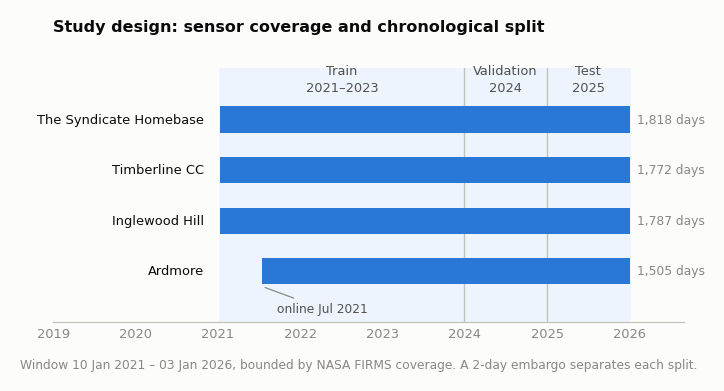

saved: fig1_study_design


In [19]:
# ===================== CELL 18 ================================================
# Figure 1 - study design: sensor coverage and the chronological split
# ==============================================================================
fig, ax = plt.subplots(figsize=(7.4, 3.0))
W0, W1 = M["date"].min(), M["date"].max()
TR = M[M.split == "train"]["date"].max()
VA = M[M.split == "val"]["date"].max()
 
ax.axvspan(W0, W1, color="#eef4fd", zorder=0)
for a, b, lab in [(W0, TR, f"Train\n{W0.year}–{TR.year}"),
                  (TR, VA, f"Validation\n{VA.year}"),
                  (VA, W1, f"Test\n{int(M[M.split == 'test']['date'].dt.year.mode()[0])}")]:
    ax.text(a + (b - a) / 2, len(SENSORS) - 0.50, lab, ha="center", va="bottom",
            fontsize=8.5, color=INK_2, linespacing=1.35)
for x in (TR, VA):
    ax.axvline(x, color=BASELINE, lw=0.9, zorder=2)
 
LABEL_X = W0 - pd.Timedelta(days=70)
for i, row in SENSORS.iterrows():
    g = M[M["id"] == row["id"]]
    y = len(SENSORS) - 1 - i
    ax.barh(y, g["date"].max() - g["date"].min(), left=g["date"].min(),
            height=0.52, color=C1_BLUE, zorder=3)
    ax.text(LABEL_X, y, row["site"], ha="right", va="center", fontsize=8.5, color=INK)
    ax.text(g["date"].max() + pd.Timedelta(days=30), y, f"{len(g):,} days",
            ha="left", va="center", fontsize=8, color=MUTED)
 
late = SENSORS.iloc[-1]
ax.set_ylim(-1.00, len(SENSORS) + 0.02)
ax.set_xlim(W0 - pd.Timedelta(days=740), W1 + pd.Timedelta(days=240))
ax.set_yticks([])
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
tidy(ax, ygrid=False)
ax.spines["left"].set_visible(False)
ax.set_title("Study design: sensor coverage and chronological split", loc="left", pad=24)
ax.annotate(f"online {late['start']:%b %Y}",
            xy=(late["start"], -0.30),
            xytext=(late["start"] + pd.Timedelta(days=66), -0.74),
            fontsize=8, color=INK_2, ha="left", va="center",
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
caption(fig, f"Window {W0:%d %b %Y} – {W1:%d %b %Y}, bounded by NASA FIRMS coverage. "
             f"A 2-day embargo separates each split.", y=0.0)
save(fig, "fig1_study_design")

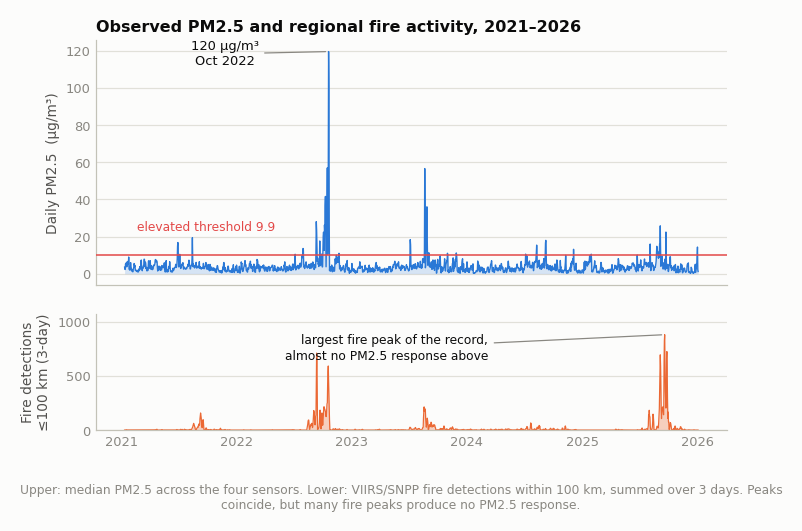

saved: fig2_timeseries


In [20]:
# ============================== CELL 19 =======================================
# Figure 2 - observed PM2.5 and regional fire activity through time
# ==============================================================================
d = (M.groupby("date").agg(pm25=("pm25_current", "median"),
                           fire=("fire_count_100km_3d", "first")).reset_index())
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7.4, 4.6), sharex=True,
                               gridspec_kw=dict(height_ratios=[2.1, 1], hspace=0.16))
ax1.fill_between(d["date"], d["pm25"], color=C1_BLUE, alpha=0.18, lw=0)
ax1.plot(d["date"], d["pm25"], color=C1_BLUE, lw=0.9)
ax1.axhline(THRESH, color=C8_RED, lw=1.0, zorder=4)
ax1.text(d["date"].min() + pd.Timedelta(days=40), THRESH + 0.10 * d["pm25"].max(),
         f"elevated threshold {THRESH:.1f}", ha="left", va="bottom",
         fontsize=8, color=C8_RED)
peak = d.loc[d["pm25"].idxmax()]
ax1.annotate(f"{peak['pm25']:.0f} µg/m³\n{peak['date']:%b %Y}",
             xy=(peak["date"], peak["pm25"]),
             xytext=(peak["date"] - pd.Timedelta(days=330), peak["pm25"] * 0.94),
             fontsize=8.5, color=INK, ha="center",
             arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
ax1.set_ylabel("Daily PM2.5  (µg/m³)")
ax1.set_title(f"Observed PM2.5 and regional fire activity, {W0.year}–{W1.year}", loc="left")
tidy(ax1)
 
ax2.fill_between(d["date"], d["fire"], color=C2_ORANGE, alpha=0.30, lw=0)
ax2.plot(d["date"], d["fire"], color=C2_ORANGE, lw=0.8)
fpk = d.loc[d["fire"].idxmax()]
ax2.annotate("largest fire peak of the record,\nalmost no PM2.5 response above",
             xy=(fpk["date"], fpk["fire"]),
             xytext=(fpk["date"] - pd.Timedelta(days=560), fpk["fire"] * 0.86),
             fontsize=8, color=INK, ha="right", va="center", linespacing=1.35,
             arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
ax2.set_ylabel("Fire detections\n≤100 km (3-day)")
ax2.set_ylim(0, d["fire"].max() * 1.22)
ax2.xaxis.set_major_locator(mdates.YearLocator())
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
tidy(ax2)
caption(fig, "Upper: median PM2.5 across the four sensors. Lower: VIIRS/SNPP fire detections "
             "within 100 km, summed over 3 days. Peaks coincide, but many fire peaks "
             "produce no PM2.5 response.", y=0.005)
save(fig, "fig2_timeseries")

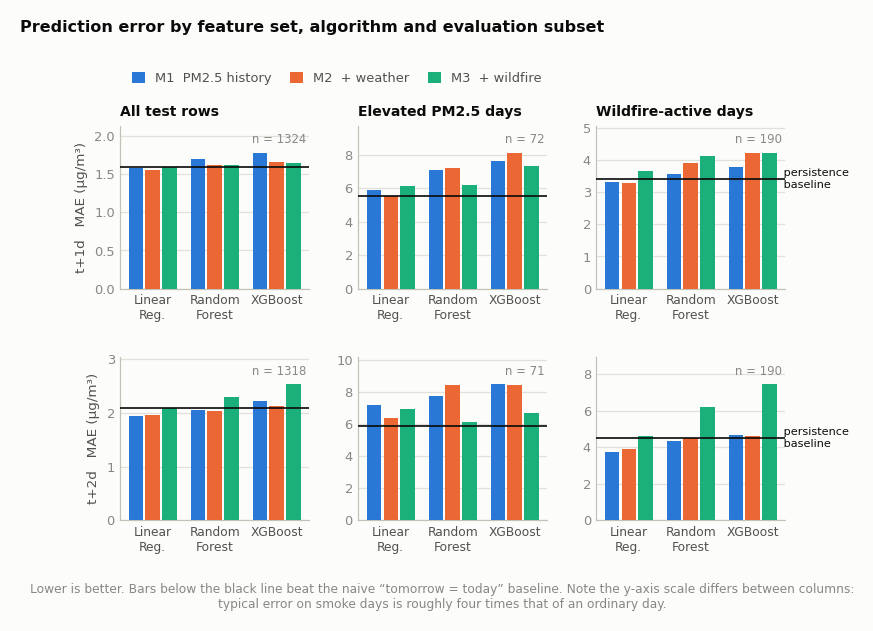

saved: fig3_mae_by_subset


In [21]:
# ============================== CELL 20 =======================================
# Figure 3 - MAE by feature set, algorithm and evaluation subset
# ==============================================================================
fig, axes = plt.subplots(2, 3, figsize=(7.8, 5.2))
fig.subplots_adjust(hspace=0.42, wspace=0.26, top=0.80)
for r, h in enumerate([1, 2]):
    for c, sub in enumerate(SUBSETS):
        ax = axes[r, c]
        base = mae(sub, h, "Persistence", "baseline")
        x = np.arange(len(ALGOS)); w = 0.27
        top = 0
        for k, mdl in enumerate(MODELS):
            vals = [mae(sub, h, a, mdl) for a in ALGOS]
            top = max(top, max(vals))
            ax.bar(x + (k - 1) * w, vals, w * 0.86, color=MODEL_COLOR[mdl],
                   label=MODEL_LABEL[mdl] if (r == 0 and c == 0) else None, zorder=3)
        ax.axhline(base, color=INK, lw=1.1, zorder=4)
        # each panel keeps its own scale: error on smoke days is ~4x an ordinary day
        ax.set_ylim(0, max(top, base) * 1.20)
        ax.text(0.985, 0.955, f"n = {NS[sub][h]}", transform=ax.transAxes,
                ha="right", va="top", fontsize=7.6, color=MUTED)
        if c == 2:
            ax.text(x[-1] + 0.44, base, " persistence\n baseline", ha="left", va="center",
                    fontsize=7.4, color=INK, linespacing=1.25)
        ax.set_xticks(x)
        ax.set_xticklabels(["Linear\nReg.", "Random\nForest", "XGBoost"],
                           fontsize=8, color=INK_2)
        tidy(ax)
        if c == 0:
            ax.set_ylabel(f"t+{h}d   MAE (µg/m³)", fontsize=8.8)
        if r == 0:
            ax.set_title(sub, loc="left", fontsize=9.2, pad=6)
axes[0, 0].legend(loc="upper left", bbox_to_anchor=(0, 1.40), ncol=3,
                  columnspacing=1.4, handlelength=1.0, handleheight=0.9)
fig.suptitle("Prediction error by feature set, algorithm and evaluation subset",
             x=0.008, y=0.985, ha="left", fontsize=10.5, fontweight="bold", color=INK)
caption(fig, "Lower is better. Bars below the black line beat the naive "
             "“tomorrow = today” baseline. Note the y-axis scale differs between "
             "columns: typical error on smoke days is roughly four times that of an "
             "ordinary day.", y=0.0)
save(fig, "fig3_mae_by_subset")

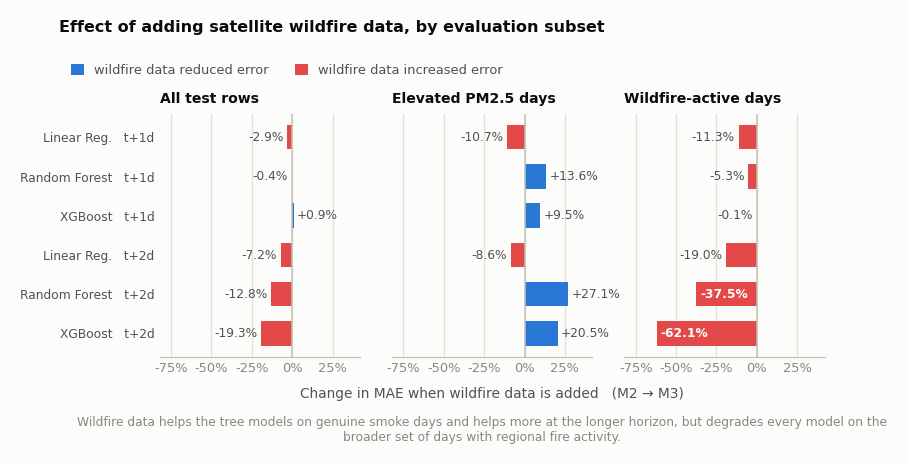

saved: fig4_wildfire_effect


In [22]:
# ============================== CELL 21 =======================================
# Figure 4 - HEADLINE: does adding satellite wildfire data help? (M2 -> M3)
# ==============================================================================
PCT = {}
for sub in SUBSETS:
    labels, vals = [], []
    for h in [1, 2]:
        for a in ALGOS:
            m2, m3 = mae(sub, h, a, "M2"), mae(sub, h, a, "M3")
            labels.append(f"{a.replace('Linear Regression', 'Linear Reg.')}   t+{h}d")
            vals.append((m2 - m3) / m2 * 100)
    PCT[sub] = (labels, vals)
 
allv = [v for lab, vv in PCT.values() for v in vv]
# Force zero into range regardless of the sign mix in allv, so the
# axvline(0) baseline is always visible and no bar can be clipped off.
XLO = min(0, min(allv) * 1.32)
XHI = max(0, max(allv) * 1.55)
 
fig, axes = plt.subplots(1, 3, figsize=(7.8, 3.5), sharey=True)
fig.subplots_adjust(wspace=0.16, top=0.74)
for c, sub in enumerate(SUBSETS):
    ax = axes[c]
    labels, vals = PCT[sub]
    colors = [DIV_POS if v > 0 else DIV_NEG for v in vals]
    y = np.arange(len(labels))[::-1]
    ax.barh(y, vals, 0.62, color=colors, zorder=3)
    ax.axvline(0, color=BASELINE, lw=1.0, zorder=4)
    span = XHI - XLO
    for yi, v in zip(y, vals):
        inside = abs(v) > 0.24 * span          # long bars carry the label inside
        if inside:
            xoff, ha = (0.02 * span, "left") if v < 0 else (-0.02 * span, "right")
        else:
            xoff, ha = (0.018 * span, "left") if v >= 0 else (-0.018 * span, "right")
        ax.text(v + xoff, yi, f"{v:+.1f}%", va="center", ha=ha, fontsize=8,
                fontweight="bold" if inside else "normal",
                color="white" if inside else INK_2, zorder=5)
    ax.set_yticks(y)
    if c == 0:
        ax.set_yticklabels(labels, fontsize=8, color=INK_2)
    else:
        ax.tick_params(labelleft=False)   # never set_yticklabels([]) on a shared axis
    ax.set_xlim(XLO, XHI)
    ax.xaxis.set_major_locator(mticker.MultipleLocator(25))
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"{v:.0f}%"))
    ax.set_title(sub, loc="left", fontsize=9.2, pad=7)
    tidy(ax, xgrid=True, ygrid=False)
    ax.spines["left"].set_visible(False)
axes[1].set_xlabel("Change in MAE when wildfire data is added   (M2 → M3)", labelpad=8)
fig.legend(handles=[Patch(facecolor=DIV_POS, label="wildfire data reduced error"),
                    Patch(facecolor=DIV_NEG, label="wildfire data increased error")],
           loc="upper left", bbox_to_anchor=(0.008, 0.90), ncol=2,
           handlelength=1.0, handleheight=0.9, frameon=False)
fig.suptitle("Effect of adding satellite wildfire data, by evaluation subset",
             x=0.008, y=0.985, ha="left", fontsize=10.5, fontweight="bold", color=INK)
caption(fig, "Wildfire data helps the tree models on genuine smoke days and helps more at the "
             "longer horizon, but degrades every model on the broader set of days with "
             "regional fire activity.", y=-0.045)
save(fig, "fig4_wildfire_effect")

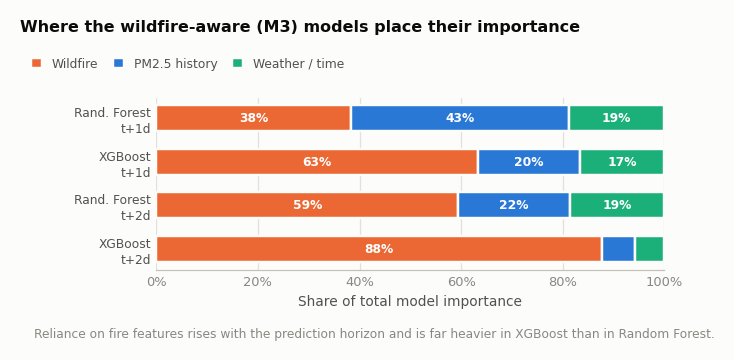

saved: fig5a_importance_composition


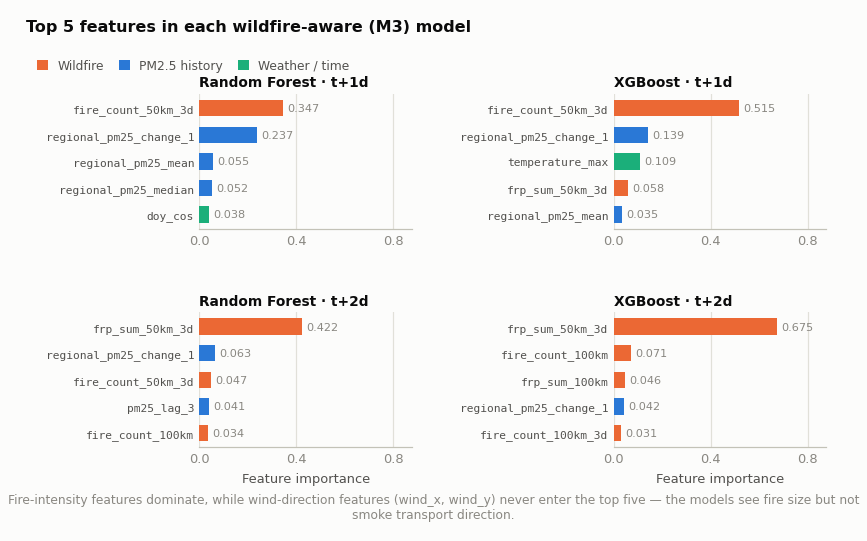

saved: fig5b_top_features


In [23]:
# ============================== CELL 22 =======================================
# Figures 5a and 5b - where the M3 models place their importance
# ==============================================================================
GROUP_COLOR = {"Wildfire": C2_ORANGE, "PM2.5 history": C1_BLUE, "Weather / time": C3_AQUA}
TREE_ALGOS = [a for a in ["Random Forest", "XGBoost"] if (IMP["algo_label"] == a).any()]
PANELS = [(a, h) for h in (1, 2) for a in TREE_ALGOS]
 
comp = []
for a, h in PANELS:
    s = IMP[(IMP.algo_label == a) & (IMP.horizon == h)]
    tot = s["importance"].sum()
    row = {"algo": a, "h": h}
    for g in GROUP_COLOR:
        row[g] = s[s.group == g]["importance"].sum() / tot * 100
    comp.append(row)
comp = pd.DataFrame(comp)
 
# ---- 5a: composition ----
fig, ax = plt.subplots(figsize=(6.6, 2.9))
fig.subplots_adjust(left=0.20, top=0.74, bottom=0.20)
labels = [f"{r.algo.replace('Random Forest', 'Rand. Forest')}\nt+{r.h}d"
          for r in comp.itertuples()]
y = np.arange(len(comp))[::-1]
left = np.zeros(len(comp))
for g in ["Wildfire", "PM2.5 history", "Weather / time"]:
    ax.barh(y, comp[g], 0.6, left=left, color=GROUP_COLOR[g], label=g,
            edgecolor=SURFACE, linewidth=1.6, zorder=3)
    for yi, l, v in zip(y, left, comp[g]):
        if v >= 12:
            ax.text(l + v / 2, yi, f"{v:.0f}%", ha="center", va="center",
                    fontsize=8, color="white", fontweight="bold")
    left = left + comp[g].values
ax.set_yticks(y)
ax.set_yticklabels(labels, fontsize=8, color=INK_2, linespacing=1.3)
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"{v:.0f}%"))
ax.set_xlabel("Share of total model importance")
fig.legend(loc="upper left", bbox_to_anchor=(0.012, 0.90), ncol=3, columnspacing=1.2,
           handlelength=0.9, handleheight=0.9, fontsize=8, frameon=False)
tidy(ax, xgrid=True, ygrid=False)
ax.spines["left"].set_visible(False)
fig.suptitle("Where the wildfire-aware (M3) models place their importance",
             x=0.012, y=0.985, ha="left", fontsize=10.5, fontweight="bold", color=INK)
caption(fig, "Reliance on fire features rises with the prediction horizon and is far "
             "heavier in XGBoost than in Random Forest.", y=0.02)
save(fig, "fig5a_importance_composition")
 
# ---- 5b: top five features per model ----
TOPN = 5
tops = {}
for a, h in PANELS:
    s = (IMP[(IMP.algo_label == a) & (IMP.horizon == h)]
         .nlargest(TOPN, "importance")[["feature", "importance", "group"]])
    tops[f"{a} · t+{h}d"] = list(s.itertuples(index=False, name=None))
XMAX = max(v for f in tops.values() for _, v, _ in f) * 1.30
 
nrow = int(np.ceil(len(tops) / 2))
fig, axes = plt.subplots(nrow, 2, figsize=(7.6, 2.2 * nrow))
fig.subplots_adjust(wspace=0.95, hspace=0.62, top=0.84, left=0.22, right=0.97)
for ax2, (panel, feats) in zip(np.atleast_1d(axes).ravel(), tops.items()):
    names = [f[0] for f in feats][::-1]
    vals = [f[1] for f in feats][::-1]
    cols = [GROUP_COLOR[f[2]] for f in feats][::-1]
    yy = np.arange(len(names))
    ax2.barh(yy, vals, 0.62, color=cols, zorder=3)
    for yi, v in zip(yy, vals):
        ax2.text(v + 0.02 * XMAX, yi, f"{v:.3f}", va="center", fontsize=7.4, color=MUTED)
    ax2.set_yticks(yy)
    ax2.set_yticklabels(names, fontsize=7.4, color=INK_2, fontfamily="DejaVu Sans Mono")
    ax2.set_xlim(0, XMAX)
    ax2.xaxis.set_major_locator(mticker.MultipleLocator(0.4))
    ax2.set_title(panel, loc="left", fontsize=9.0, pad=5)
    tidy(ax2, xgrid=True, ygrid=False)
    ax2.spines["left"].set_visible(False)
for ax2 in np.atleast_2d(axes)[-1]:
    ax2.set_xlabel("Feature importance", fontsize=8.5)
fig.legend(handles=[Patch(facecolor=GROUP_COLOR[g], label=g) for g in
                    ["Wildfire", "PM2.5 history", "Weather / time"]],
           loc="upper left", bbox_to_anchor=(0.012, 0.935), ncol=3, columnspacing=1.2,
           handlelength=0.9, handleheight=0.9, fontsize=8, frameon=False)
fig.suptitle(f"Top {TOPN} features in each wildfire-aware (M3) model",
             x=0.012, y=0.995, ha="left", fontsize=10.5, fontweight="bold", color=INK)
caption(fig, "Fire-intensity features dominate, while wind-direction features "
             "(wind_x, wind_y) never enter the top five — the models see fire size but "
             "not smoke transport direction.", y=0.015)
save(fig, "fig5b_top_features")

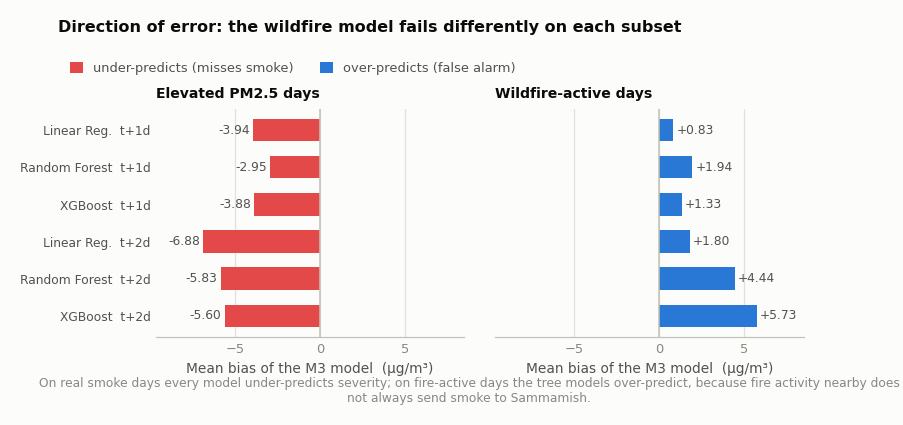

saved: fig6_mean_bias


In [24]:
# ============================== CELL 23 =======================================
# Figure 6 - direction of error (mean bias of the M3 models)
# ==============================================================================
BIAS = {}
for sub in ["Elevated PM2.5 days", "Wildfire-active days"]:
    labels, vals = [], []
    for h in [1, 2]:
        for a in ALGOS:
            s = R[(R.subset == sub) & (R.horizon == h) & (R.algo == a) & (R.model == "M3")]
            labels.append(f"{a.replace('Linear Regression', 'Linear Reg.')}  t+{h}d")
            vals.append(float(s["Bias"].iloc[0]))
    BIAS[sub] = (labels, vals)
bv = [v for _, vv in BIAS.values() for v in vv]
BLO, BHI = min(bv) - 0.22 * (max(bv) - min(bv)), max(bv) + 0.22 * (max(bv) - min(bv))
 
fig, axes = plt.subplots(1, 2, figsize=(7.6, 3.3), sharey=True)
fig.subplots_adjust(wspace=0.10, top=0.74)
for c, sub in enumerate(["Elevated PM2.5 days", "Wildfire-active days"]):
    ax = axes[c]
    labels, vals = BIAS[sub]
    colors = [DIV_POS if v > 0 else DIV_NEG for v in vals]
    y = np.arange(len(labels))[::-1]
    ax.barh(y, vals, 0.6, color=colors, zorder=3)
    ax.axvline(0, color=BASELINE, lw=1.0, zorder=4)
    off = 0.01 * (BHI - BLO)
    for yi, v in zip(y, vals):
        ax.text(v + (off if v >= 0 else -off), yi, f"{v:+.2f}", va="center",
                ha="left" if v >= 0 else "right", fontsize=8, color=INK_2)
    ax.set_yticks(y)
    if c == 0:
        ax.set_yticklabels(labels, fontsize=8, color=INK_2)
    else:
        ax.tick_params(labelleft=False)
    ax.set_xlim(BLO, BHI)
    ax.set_title(sub, loc="left", fontsize=9.2, pad=7)
    ax.set_xlabel("Mean bias of the M3 model  (µg/m³)")
    tidy(ax, xgrid=True, ygrid=False)
    ax.spines["left"].set_visible(False)
fig.legend(handles=[Patch(facecolor=DIV_NEG, label="under-predicts (misses smoke)"),
                    Patch(facecolor=DIV_POS, label="over-predicts (false alarm)")],
           loc="upper left", bbox_to_anchor=(0.008, 0.90), ncol=2,
           handlelength=1.0, handleheight=0.9, frameon=False)
fig.suptitle("Direction of error: the wildfire model fails differently on each subset",
             x=0.008, y=0.985, ha="left", fontsize=10.5, fontweight="bold", color=INK)
caption(fig, "On real smoke days every model under-predicts severity; on fire-active days "
             "the tree models over-predict, because fire activity nearby does not always "
             "send smoke to Sammamish.", y=0.0)
save(fig, "fig6_mean_bias")

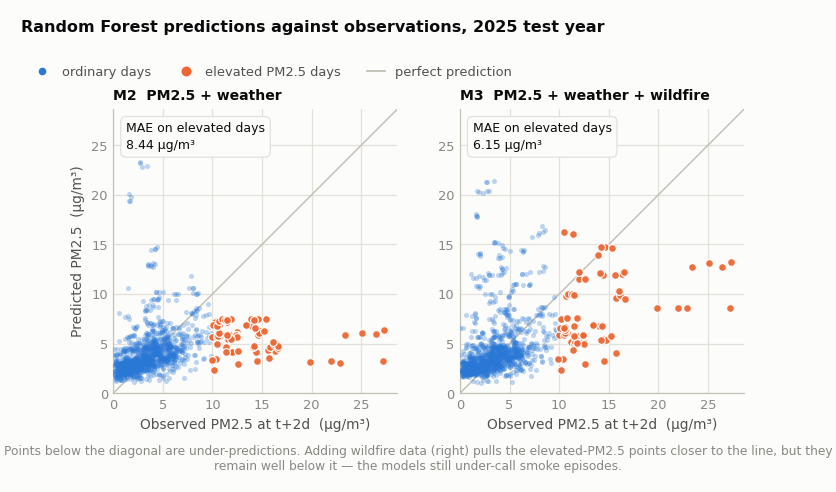

saved: fig7_pred_vs_obs


In [25]:
# ============================== CELL 24 =======================================
# Figure 7 - predicted vs observed. This cell refits two Random Forests, so it
# is the slowest of the figure cells (most of the times around 20-40 seconds).
# ==============================================================================
from sklearn.ensemble import RandomForestRegressor

tr, te = M[M.split == "train"], M[M.split == "test"]
YCOL, MASKCOL = "target_pm25_t2", "mask_elevated_t2"

panels = [("M2", M2_FEATS, "M2  PM2.5 + weather"),
          ("M3", M3_FEATS, "M3  PM2.5 + weather + wildfire")]

# Fit first, then size the axes off the ACTUAL obs/pred range (not a percentile),
# so the most extreme smoke-day points are never clipped off the plot.
panel_data = []
for mdl, cols, name in panels:
    t = tr.dropna(subset=cols + [YCOL])
    s = te.dropna(subset=cols + [YCOL])
    rf = RandomForestRegressor(random_state=42, n_jobs=1).fit(t[cols], t[YCOL])
    pred = rf.predict(s[cols])
    obs = s[YCOL].values
    hi = s[MASKCOL].values == 1
    panel_data.append((name, obs, pred, hi))

LIM = max(max(obs.max(), pred.max()) for _, obs, pred, _ in panel_data) * 1.05

fig, axes = plt.subplots(1, 2, figsize=(7.4, 3.9))
fig.subplots_adjust(top=0.80, wspace=0.22)
for c, (name, obs, pred, hi) in enumerate(panel_data):
    ax = axes[c]
    ax.plot([0, LIM], [0, LIM], color=BASELINE, lw=1.0, zorder=2)
    ax.scatter(obs[~hi], pred[~hi], s=11, color=C1_BLUE, alpha=0.30, linewidths=0, zorder=3)
    ax.scatter(obs[hi], pred[hi], s=26, color=C2_ORANGE, alpha=0.95,
               edgecolors=SURFACE, linewidths=0.8, zorder=4)
    ax.set_xlim(0, LIM); ax.set_ylim(0, LIM)
    ax.set_xlabel("Observed PM2.5 at t+2d  (µg/m³)")
    if c == 0:
        ax.set_ylabel("Predicted PM2.5  (µg/m³)")
    ax.set_title(name, loc="left", fontsize=9.2, pad=6)
    # sits in the empty upper-left wedge, on a surface plate so no dot shows through
    ax.text(0.045, 0.955, f"MAE on elevated days\n{np.abs(pred[hi] - obs[hi]).mean():.2f} µg/m³",
            transform=ax.transAxes, ha="left", va="top", fontsize=8.2, color=INK,
            linespacing=1.4, zorder=6,
            bbox=dict(boxstyle="round,pad=0.42", facecolor=SURFACE,
                      edgecolor=GRID, linewidth=0.8))
    ax.set_aspect("equal")
    tidy(ax, xgrid=True)
fig.legend(handles=[
    Line2D([], [], marker="o", linestyle="none", markersize=5,
           markerfacecolor=C1_BLUE, markeredgecolor="none", label="ordinary days"),
    Line2D([], [], marker="o", linestyle="none", markersize=6.5,
           markerfacecolor=C2_ORANGE, markeredgecolor="none", label="elevated PM2.5 days"),
    Line2D([], [], color=BASELINE, lw=1.2, label="perfect prediction")],
    loc="upper left", bbox_to_anchor=(0.012, 0.915), ncol=3, handlelength=1.4, frameon=False)
TEST_YEAR = int(te["date"].dt.year.mode()[0])   # not .max(): the split runs a few days into Jan
fig.suptitle(f"Random Forest predictions against observations, {TEST_YEAR} test year",
             x=0.012, y=0.995, ha="left", fontsize=10.5, fontweight="bold", color=INK)
caption(fig, "Points below the diagonal are under-predictions. Adding wildfire data (right) "
             "pulls the elevated-PM2.5 points closer to the line, but they remain well below "
             "it — the models still under-call smoke episodes.", y=0.005)
save(fig, "fig7_pred_vs_obs")


In [26]:
# ============================== CELL 25 =======================================
# Tables 1-5, written as CSV so they can be pasted into Word and restyled
# ==============================================================================
rows = []
for key, name in [("train", "Train"), ("val", "Validation"), ("test", "Test")]:
    sub = M[M.split == key]
    rows.append({
        "Split": name,
        "Start": sub["date"].min().date(), "End": sub["date"].max().date(),
        "Rows": len(sub),
        "Sensor-days with elevated PM2.5 (t+1d)": int(sub["mask_elevated_t1"].sum()),
        "Wildfire-active rows": int(sub["mask_fire_active"].sum()),
        "Mean PM2.5": round(sub["pm25_current"].mean(), 2),
        "Max PM2.5": round(sub["pm25_current"].max(), 1),
    })
t1 = pd.DataFrame(rows)
 
rows = []
for _, r in SENSORS.iterrows():
    g = M[M["id"] == r["id"]]
    rows.append({"Sensor ID": r["id"], "Site": r["site"],
                 "First day": g["date"].min().date(), "Last day": g["date"].max().date(),
                 "Years": round((g["date"].max() - g["date"].min()).days / 365.25, 2),
                 "Modelled rows": len(g),
                 "Interpolated rows": int(g["pm25_is_interp"].sum())})
t2 = pd.DataFrame(rows)
 
t3 = (R.assign(Horizon=lambda x: "t+" + x["horizon"].astype(str) + "d")
        .rename(columns={"subset": "Subset", "algo": "Algorithm", "model": "Feature set",
                         "Bias": "Mean bias"})
        [["Subset", "Horizon", "Algorithm", "Feature set", "MAE", "RMSE", "R2", "Mean bias"]]
        .round(4)
        .sort_values(["Subset", "Horizon", "Algorithm", "Feature set"]))
 
rows = []
for sub in SUBSETS:
    for h in [1, 2]:
        for a in ALGOS:
            m1, m2, m3 = (mae(sub, h, a, m) for m in MODELS)
            rows.append({"Subset": sub, "Horizon": f"t+{h}d", "Algorithm": a,
                         "M1 MAE": round(m1, 3), "M2 MAE": round(m2, 3), "M3 MAE": round(m3, 3),
                         "M1→M2 gain": round(m1 - m2, 3),
                         "M2→M3 gain": round(m2 - m3, 3),
                         "M2→M3 gain %": round((m2 - m3) / m2 * 100, 1)})
t4 = pd.DataFrame(rows)
 
t5 = (comp.rename(columns={"algo": "Algorithm", "h": "Horizon",
                           "Wildfire": "Wildfire %", "PM2.5 history": "PM2.5 history %",
                           "Weather / time": "Weather/time %"})
          .assign(Horizon=lambda x: "t+" + x["Horizon"].astype(str) + "d").round(1))
 
for t, n in [(t1, "table1_dataset_and_splits"), (t2, "table2_sensor_coverage"),
             (t3, "table3_test_metrics_full"), (t4, "table4_mae_improvement"),
             (t5, "table5_importance_composition")]:
    t.to_csv(f"{FIGDIR}/{n}.csv", index=False)
    print(f"{n}.csv  ({len(t)} rows)")
 
print("\n--- Table 1: dataset and splits ---"); print(t1.to_string(index=False))
print("\n--- Table 2: sensor coverage ---");     print(t2.to_string(index=False))
print("\n--- Table 4: MAE improvement ---");     print(t4.to_string(index=False))
print("\n--- Table 5: importance composition ---"); print(t5.to_string(index=False))

table1_dataset_and_splits.csv  (3 rows)
table2_sensor_coverage.csv  (4 rows)
table3_test_metrics_full.csv  (60 rows)
table4_mae_improvement.csv  (18 rows)
table5_importance_composition.csv  (4 rows)

--- Table 1: dataset and splits ---
     Split      Start        End  Rows  Sensor-days with elevated PM2.5 (t+1d)  Wildfire-active rows  Mean PM2.5  Max PM2.5
     Train 2021-01-10 2023-12-29  4054                                     199                   412        4.45      123.4
Validation 2024-01-01 2024-12-29  1456                                      35                    16        3.31       19.7
      Test 2025-01-01 2026-01-03  1356                                      72                   192        3.98       27.3

--- Table 2: sensor coverage ---
 Sensor ID                   Site  First day   Last day  Years  Modelled rows  Interpolated rows
     77531 The Syndicate Homebase 2021-01-10 2026-01-03   4.98           1818                  5
     81955          Timberline CC 2021-0

In [27]:
# ============================== CELL 26 =======================================
# Bundle everything into one zip for a single download from the Output panel
# ==============================================================================
zip_path = shutil.make_archive(f"{WORK}/AQ_Research_Figures", "zip", FIGDIR)
print("wrote:", zip_path, f"({os.path.getsize(zip_path) / 1e6:.1f} MB)")
print("\ncontents:")
for f in sorted(os.listdir(FIGDIR)):
    print("  ", f)

wrote: /kaggle/working/AQ_Research_Figures.zip (1.8 MB)

contents:
   fig1_study_design.pdf
   fig1_study_design.png
   fig2_timeseries.pdf
   fig2_timeseries.png
   fig3_mae_by_subset.pdf
   fig3_mae_by_subset.png
   fig4_wildfire_effect.pdf
   fig4_wildfire_effect.png
   fig5a_importance_composition.pdf
   fig5a_importance_composition.png
   fig5b_top_features.pdf
   fig5b_top_features.png
   fig6_mean_bias.pdf
   fig6_mean_bias.png
   fig7_pred_vs_obs.pdf
   fig7_pred_vs_obs.png
   table1_dataset_and_splits.csv
   table2_sensor_coverage.csv
   table3_test_metrics_full.csv
   table4_mae_improvement.csv
   table5_importance_composition.csv
